# Predicting Goals Scored by a Team in a FIFA World Cup 2026 Match
### Linear Regression 2.2 — build, evaluate and compare predictive models

**Objective.** Build and evaluate a linear regression model that predicts the number of goals a team scores in a single World Cup 2026 match, using only information that is known before kick-off.

**Data.** `Linear_regression_2_2_datasets.xlsx` — 208 rows (104 matches × 2 teams), 8 explanatory variables, target `Goal_Scored`.

### How this notebook maps to the marking rubric

| Rubric expectation | Where it is covered |
|---|---|
| Dataset relevant, requirements met, appropriate linear technique | Steps 2, 6, 10 |
| Cross-validation | Steps 4 to 11 (repeated, match-grouped CV, nested tuning, locked hold-out set) |
| Correct interpretation of results | Steps 6, 7, 12 |
| Comprehensive, relevant EDA with professional visuals | Step 3 |
| Feature engineering / data transformation | Step 8 |
| In-depth model and feature analysis | Steps 6, 7, 12 |
| Systematic experiments and measurable optimisation | Steps 8, 9 |
| Competing algorithms compared, with recommendations | Steps 9, 10, 14 |
| Data storytelling through visuals | Throughout, mainly Steps 3, 11, 12 |

### How to run
Place this notebook and `Linear_regression_2_2_datasets.xlsx` in the same folder, then use **Kernel → Restart & Run All**. All random seeds are fixed, so results are reproducible.

## Step 1 — Setup
Import libraries, fix the random seed, and set a consistent plotting style.

In [1]:
import warnings
warnings.filterwarnings("ignore",
    message=r".*sklearn\.utils\.parallel\.delayed.*",
    category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, PoissonRegressor, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
C = {"main": "#1f4e79", "accent": "#e07b39", "good": "#2a9d8f", "bad": "#c8553d", "grey": "#8d99ae"}

DATA_PATH = "../dataset/Linear_regression 2.2 datasets.xlsx"

## Step 2 — Load, understand and validate the data

Before any modelling, confirm the data is what we think it is. Three things matter most here:

1. **Structure** — each match appears twice (once per team), so rows from the same match are *not independent*. This drives how we validate the model later.
2. **Consistency** — the two rows of a match must mirror each other (e.g. `Rank_Diff` should be equal and opposite).
3. **No leakage** — every explanatory variable must be known *before* the match starts.

Long column names are shortened for readable tables and plots; the data dictionary shows the mapping.

In [2]:
raw = pd.read_excel(DATA_PATH)

RENAME = {
    "Squad_Avg_Age": "Age",
    "Team_Goals_per_Game_Last_3": "Goals_pg3",
    "Team_SOT_per_Game_Last_3": "SOT_pg3",
    "Striker_Bench_Count": "Strikers_Bench",
    "FIFA_Ranking_Difference": "Rank_Diff",
    "Team_Corner_Won_per_Game_Last_3": "Corners_pg3",
    "Knockout_Stage_Appearances_Last_10_FIFA": "KO_Apps",
    "Opponent_GK_Save_last_3": "Opp_GK_Saves3",
    "Goal_Scored": "Goals",
}
df = raw.rename(columns=RENAME).copy()

TARGET = "Goals"
BASE = ["Age", "Goals_pg3", "SOT_pg3", "Strikers_Bench", "Rank_Diff", "Corners_pg3", "KO_Apps", "Opp_GK_Saves3"]

dictionary = pd.DataFrame([
    ["Age", "Squad_Avg_Age", "Average age of the squad", "Yes"],
    ["Goals_pg3", "Team_Goals_per_Game_Last_3", "Goals scored per game by the team in its last 3 matches", "Yes"],
    ["SOT_pg3", "Team_SOT_per_Game_Last_3", "Shots on target per game by the team in its last 3 matches", "Yes"],
    ["Strikers_Bench", "Striker_Bench_Count", "Striker bench count, as recorded in the sheet", "Yes"],
    ["Rank_Diff", "FIFA_Ranking_Difference", "Team FIFA rank minus opponent FIFA rank (negative = better ranked team)", "Yes"],
    ["Corners_pg3", "Team_Corner_Won_per_Game_Last_3", "Corners won per game by the team in its last 3 matches", "Yes"],
    ["KO_Apps", "Knockout_Stage_Appearances_Last_10_FIFA", "Knockout-stage appearances in the last 10 FIFA tournaments, as recorded in the sheet", "Yes"],
    ["Opp_GK_Saves3", "Opponent_GK_Save_last_3", "Saves per game by the opponent's goalkeeper in the opponent's last 3 matches (a count, not a percentage)", "Yes"],
    ["Stage", "Stage", "Tournament stage of the match", "Yes (schedule)"],
    ["Goals", "Goal_Scored", "TARGET: goals scored by the team in this match", "No (outcome)"],
], columns=["Short name", "Original column", "Meaning", "Known before kick-off?"])

display(dictionary)
display(df.head())

,Short name,Original column,Meaning,Known before kick-off?
0,Age,Squad_Avg_Age,Average age of the squad,Yes
1,Goals_pg3,Team_Goals_per_Game_Last_3,Goals scored per game by the team in its last ...,Yes
2,SOT_pg3,Team_SOT_per_Game_Last_3,Shots on target per game by the team in its la...,Yes
3,Strikers_Bench,Striker_Bench_Count,"Striker bench count, as recorded in the sheet",Yes
4,Rank_Diff,FIFA_Ranking_Difference,Team FIFA rank minus opponent FIFA rank (negat...,Yes
5,Corners_pg3,Team_Corner_Won_per_Game_Last_3,Corners won per game by the team in its last 3...,Yes
6,KO_Apps,Knockout_Stage_Appearances_Last_10_FIFA,Knockout-stage appearances in the last 10 FIFA...,Yes
7,Opp_GK_Saves3,Opponent_GK_Save_last_3,Saves per game by the opponent's goalkeeper in...,Yes
8,Stage,Stage,Tournament stage of the match,Yes (schedule)
9,Goals,Goal_Scored,TARGET: goals scored by the team in this match,No (outcome)


,Match_ID,Team_Name,Opposition_Team_Name,Stage,Age,Goals_pg3,SOT_pg3,Strikers_Bench,Rank_Diff,Corners_pg3,KO_Apps,Opp_GK_Saves3,Goals
0,12-jun-me-so,Mexico,South Africa,First Stage,27.90,2.67,6.0,3,-46,6.67,8,4.33,2
1,12-jun-me-so,South Africa,Mexico,First Stage,26.81,0.67,4.0,1,46,4.00,0,4.00,0
2,12-jun-ko-cz,Korea Republic,Czechia,First Stage,28.07,2.00,6.0,3,-15,7.00,3,4.00,2
3,12-jun-ko-cz,Czechia,Korea Republic,First Stage,27.62,2.33,4.0,4,15,5.67,1,2.67,1
4,12-jun-ca-bh,Canada,Bosnia and Herzegovina,First Stage,26.97,1.00,4.0,2,-34,9.33,0,3.33,1


In [3]:
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Teams:", df["Team_Name"].nunique(), "| Matches:", df["Match_ID"].nunique())
print("Rows per match:", df.groupby("Match_ID").size().value_counts().to_dict())

# each row must have exactly one mirror row (the opponent's row in the same match)
mirror = df.merge(df, left_on=["Match_ID", "Team_Name"], right_on=["Match_ID", "Opposition_Team_Name"], suffixes=("", "_opp"))
assert len(mirror) == len(df), "mirror rows missing"
print("Rank_Diff exactly opposite in mirror rows:", bool((mirror["Rank_Diff"] == -mirror["Rank_Diff_opp"]).all()))
print("Same stage in mirror rows:", bool((mirror["Stage"] == mirror["Stage_opp"]).all()))

print("Goals are non-negative integers:", bool((df["Goals"] >= 0).all() and (df["Goals"] % 1 == 0).all()))
print("Rows where goals/game exceeds SOT/game:", int((df["Goals_pg3"] > df["SOT_pg3"]).sum()))
display(df["Stage"].value_counts().rename("rows").to_frame())

Shape: (208, 13)
Missing values: 0
Duplicate rows: 0
Teams: 48 | Matches: 104
Rows per match: {2: 104}
Rank_Diff exactly opposite in mirror rows: True
Same stage in mirror rows: True
Goals are non-negative integers: True
Rows where goals/game exceeds SOT/game: 0


,rows
Stage,
First Stage,144
Round of 32,32
Round of 16,16
Quarter final,8
Semi final,4
Bronze final,2
Final,2


**Validation outcome.** The checks above confirm there are no missing values or duplicates, every match has exactly two mirrored rows, and all explanatory variables are pre-match information, so there is no target leakage.

The key structural point is that the two rows of one match share the same game. They are therefore related, and a normal random cross-validation split could place one team's row in training and its opponent's row in testing. That leaks information about the match. **All validation in this notebook keeps both rows of a match together (grouped splits).**

## Step 3 — Exploratory data analysis (EDA)

The EDA answers five questions that directly shape the modelling decisions:

1. What does the target look like (shape, spread, count behaviour)?
2. Are the features well-behaved (skew, outliers, scale)?
3. Which features relate to goals, and how strongly?
4. Is the relationship linear, or does it bend?
5. Are the features redundant with each other (multicollinearity)?

### 3.1 Descriptive statistics

In [4]:
num_cols = BASE + [TARGET]
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,208.0,27.867,1.094,25.85,26.970,27.645,28.61,30.43,0.451,-0.592
Goals_pg3,208.0,1.752,0.856,0.00,1.000,1.670,2.33,4.00,0.046,-0.806
SOT_pg3,208.0,4.782,1.824,0.67,3.585,4.670,6.33,8.67,0.044,-0.791
Strikers_Bench,208.0,2.312,1.009,0.00,2.000,2.000,3.00,6.00,0.908,1.558
Rank_Diff,208.0,0.000,34.324,-77.00,-24.250,0.000,24.25,77.00,0.000,-0.389
Corners_pg3,208.0,4.913,2.163,0.33,3.330,4.670,6.33,13.33,0.750,0.898
KO_Apps,208.0,3.226,3.204,0.00,0.000,2.000,6.00,10.00,0.575,-1.058
Opp_GK_Saves3,208.0,2.909,1.150,0.67,2.000,2.835,3.67,6.33,0.418,-0.041
Goals,208.0,1.481,1.393,0.00,0.000,1.000,2.00,7.00,1.149,1.357


### 3.2 The target: goals scored per team per match
Goals are small non-negative counts. We compare the observed distribution with a Poisson distribution that has the same mean. If the variance is much larger than the mean the data is *over-dispersed*, which matters for how reliable a plain linear model's error assumptions are.

mean = 1.481 | variance = 1.942 | dispersion index (var/mean) = 1.311
Poisson dispersion test: chi2 = 271.4, p = 0.0018


C:\Users\DELL\AppData\Local\Temp\ipykernel_18020\257109928.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, y=TARGET, x=np.where(df["Stage"] == "First Stage", "Group stage", "Knockout"), palette=[C["main"], C["accent"]], ax=ax[1])


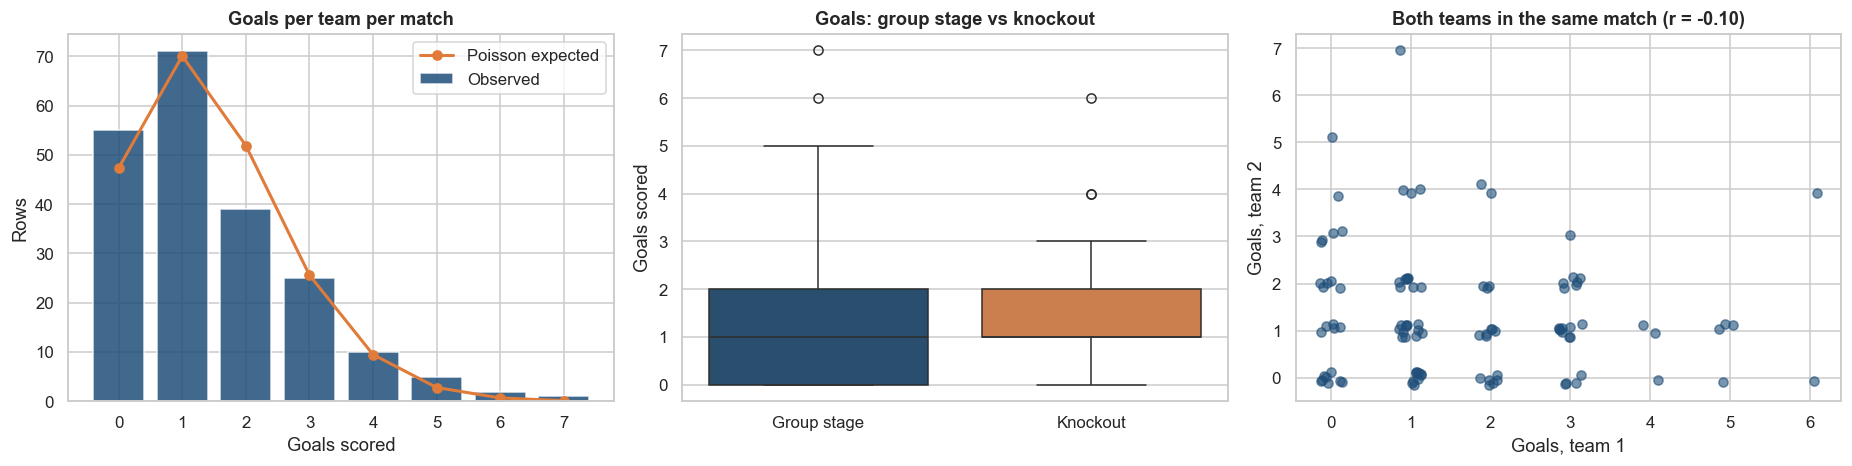

In [5]:
mean_g, var_g = df[TARGET].mean(), df[TARGET].var()
n = len(df)
disp_stat = (n - 1) * var_g / mean_g
disp_p = 1 - stats.chi2.cdf(disp_stat, n - 1)
print(f"mean = {mean_g:.3f} | variance = {var_g:.3f} | dispersion index (var/mean) = {var_g/mean_g:.3f}")
print(f"Poisson dispersion test: chi2 = {disp_stat:.1f}, p = {disp_p:.4f}")

obs = df[TARGET].value_counts().sort_index()
k = np.arange(0, int(obs.index.max()) + 1)
expected = stats.poisson.pmf(k, mean_g) * n

# the two teams in a match: are their goal counts related?
wide = df.sort_values(["Match_ID", "Team_Name"]).groupby("Match_ID")[TARGET].apply(list)
g1 = np.array([v[0] for v in wide]); g2 = np.array([v[1] for v in wide])
r_pair, p_pair = stats.pearsonr(g1, g2)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].bar(k, obs.reindex(k, fill_value=0).values, color=C["main"], alpha=0.85, label="Observed")
ax[0].plot(k, expected, "o-", color=C["accent"], lw=2, label="Poisson expected")
ax[0].set(title="Goals per team per match", xlabel="Goals scored", ylabel="Rows"); ax[0].legend()

stage_order = ["First Stage", "Round of 32", "Round of 16", "Quarter final", "Semi final", "Bronze final", "Final"]
sns.boxplot(data=df, y=TARGET, x=np.where(df["Stage"] == "First Stage", "Group stage", "Knockout"), palette=[C["main"], C["accent"]], ax=ax[1])
ax[1].set(title="Goals: group stage vs knockout", xlabel="", ylabel="Goals scored")

ax[2].scatter(g1 + np.random.uniform(-.15, .15, len(g1)), g2 + np.random.uniform(-.15, .15, len(g2)), color=C["main"], alpha=.6)
ax[2].set(title=f"Both teams in the same match (r = {r_pair:.2f})", xlabel="Goals, team 1", ylabel="Goals, team 2")
plt.tight_layout(); plt.show()

**Reading the target.** Goals are right-skewed: 0 and 1 goal account for about 60% of rows and the tail runs to 7. There are *more* zeros than a Poisson distribution with the same mean would produce (55 observed against about 47 expected) and fewer 2-goal rows, and the variance is about 31% larger than the mean (dispersion test p ≈ 0.002), so the data is mildly over-dispersed. The two teams in a match are only weakly related (r ≈ -0.10).

For modelling this means linear regression can describe the *average* goals well, but its predictions are continuous (e.g. 1.4 goals), residuals will be right-skewed rather than normal, and the spread of errors is likely to grow with the predicted mean. We check this in the diagnostics and include a Poisson model as a competing algorithm.

### 3.3 Feature distributions and outliers

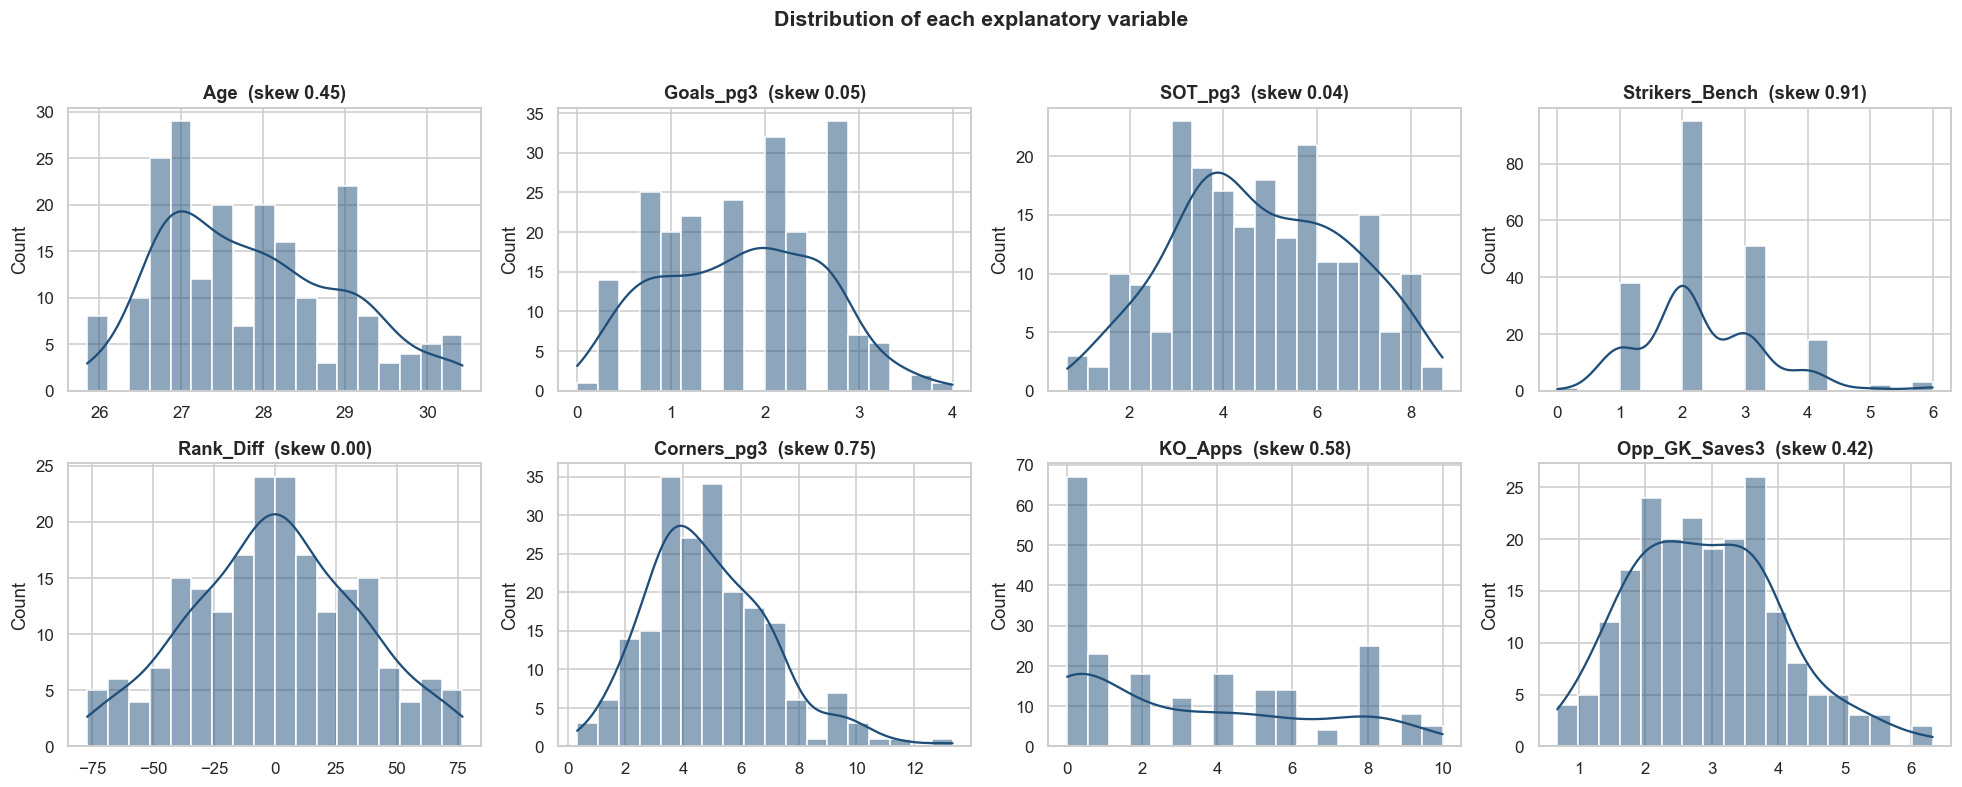

,IQR outliers,share %
Age,0,0.0
Goals_pg3,0,0.0
SOT_pg3,0,0.0
Strikers_Bench,6,2.9
Rank_Diff,0,0.0
Corners_pg3,2,1.0
KO_Apps,0,0.0
Opp_GK_Saves3,2,1.0


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), BASE):
    sns.histplot(df[col], kde=True, color=C["main"], ax=ax, bins=18)
    ax.set_title(f"{col}  (skew {df[col].skew():.2f})")
    ax.set_xlabel("")
plt.suptitle("Distribution of each explanatory variable", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

q1, q3 = df[BASE].quantile(.25), df[BASE].quantile(.75)
iqr = q3 - q1
outliers = ((df[BASE] < q1 - 1.5 * iqr) | (df[BASE] > q3 + 1.5 * iqr)).sum().rename("IQR outliers").to_frame()
outliers["share %"] = (outliers["IQR outliers"] / len(df) * 100).round(1)
display(outliers)

**Reading the distributions.** Most variables are roughly symmetric. `Strikers_Bench` (skew 0.9) and `Corners_pg3` (0.75) lean right. The IQR rule flags only a handful of points (6 rows, 2.9%, for `Strikers_Bench`; 1–2% for corners and goalkeeper saves). They are plausible real values, not data errors, so **no rows are removed**. Standardising the features later keeps their different scales from distorting regularised models.

### 3.4 Correlation structure
Pearson correlation shows linear association. The heatmap checks both feature→target signal and feature↔feature overlap.

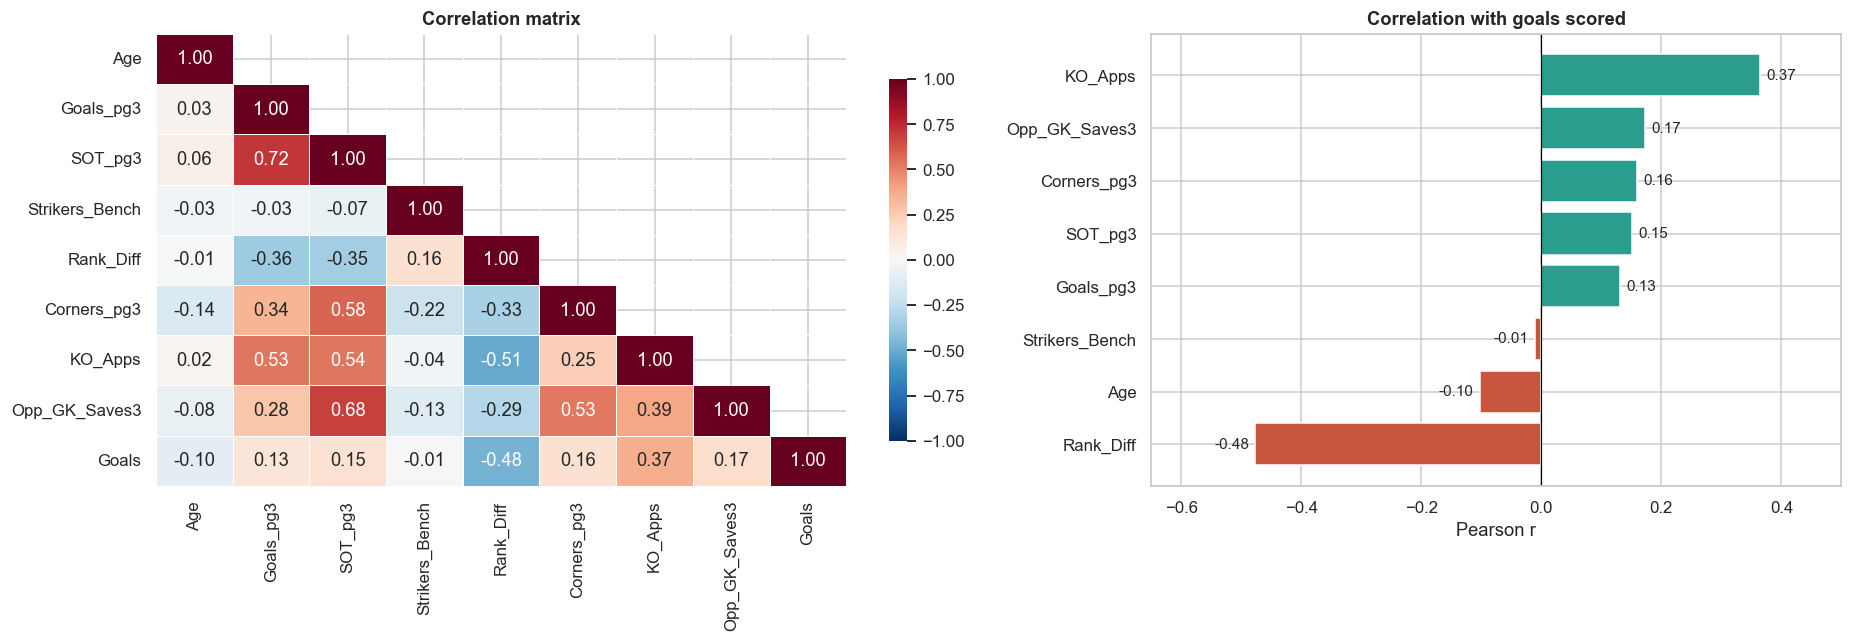

In [7]:
corr = df[BASE + [TARGET]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax[0])
ax[0].set_title("Correlation matrix")

tc = corr[TARGET].drop(TARGET).sort_values()
ax[1].barh(tc.index, tc.values, color=[C["bad"] if v < 0 else C["good"] for v in tc.values])
ax[1].axvline(0, color="black", lw=.8)
for i, v in enumerate(tc.values):
    ax[1].text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=10)
ax[1].set(title="Correlation with goals scored", xlabel="Pearson r"); ax[1].set_xlim(-0.65, 0.5)
plt.tight_layout(); plt.show()

**Reading the correlations.** `Rank_Diff` (r = -0.48) and `KO_Apps` (+0.37) are the only clearly strong signals. The recent-form variables are weak on their own (goals, shots, corners and goalkeeper saves all between 0.13 and 0.17) and `Strikers_Bench` is essentially unrelated to goals (-0.01). The heatmap also shows overlap among the explanatory variables: `Goals_pg3` and `SOT_pg3` correlate at 0.72, `SOT_pg3` and `Opp_GK_Saves3` at 0.68, and `Rank_Diff` and `KO_Apps` at -0.51.

### 3.5 Is each relationship linear? Feature vs goals with a LOWESS trend
The straight line is the linear fit; the curved line is a flexible LOWESS smoother. Where they diverge, the relationship is non-linear and a transformation may help.

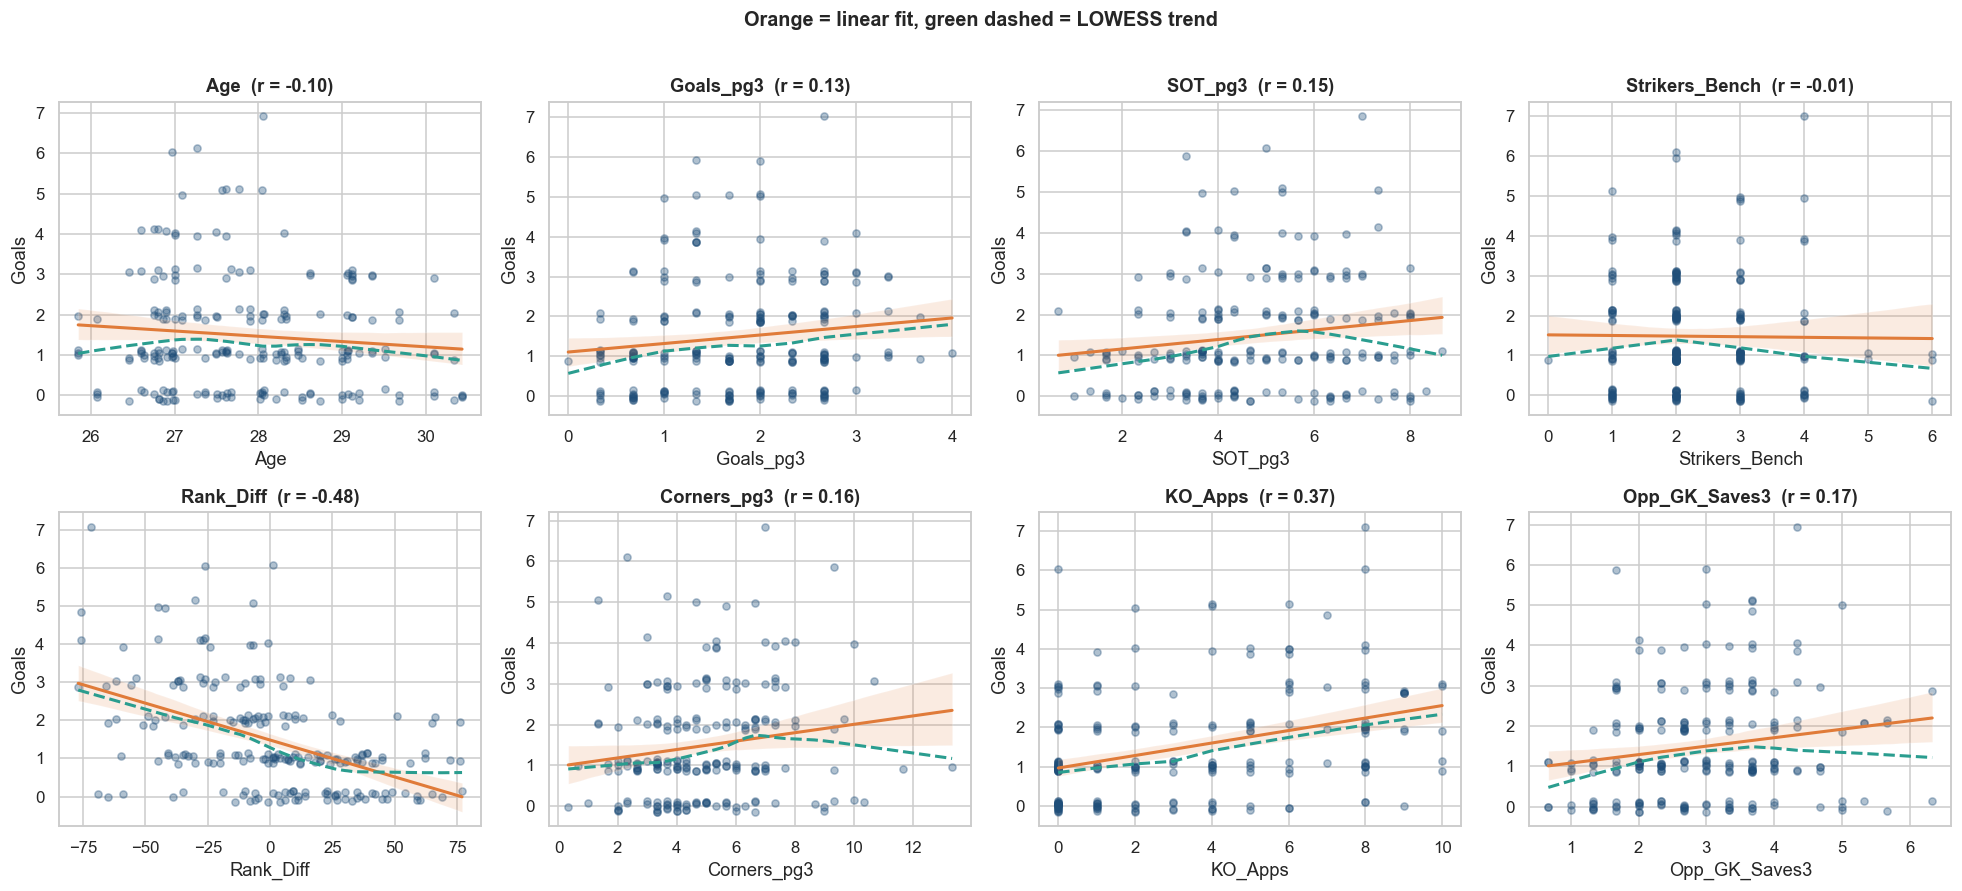

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), BASE):
    sns.regplot(data=df, x=col, y=TARGET, y_jitter=0.15, scatter_kws={"alpha": .35, "s": 22, "color": C["main"]},
                line_kws={"color": C["accent"], "lw": 2}, ax=ax, ci=95)
    sns.regplot(data=df, x=col, y=TARGET, lowess=True, scatter=False, line_kws={"color": C["good"], "lw": 2, "ls": "--"}, ax=ax)
    r = df[col].corr(df[TARGET])
    ax.set_title(f"{col}  (r = {r:.2f})"); ax.set_ylabel("Goals")
plt.suptitle("Orange = linear fit, green dashed = LOWESS trend", y=1.01, fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the trends.** The straight lines are a fair summary for `KO_Apps`, `Age` and `Strikers_Bench`. Two things stand out. (1) For `Rank_Diff` the smoother **flattens for weaker-ranked teams**: once a team is clearly the underdog, expected goals bottom out around 0.7, so the effect is not perfectly linear. A square-root style transform of the gap is therefore worth testing. (2) For shots on target, corners and opponent goalkeeper saves the trend rises and then levels or dips at high values, a sign of diminishing returns and of few observations in the extremes.

### 3.6 The strongest story: ranking gap vs goals
`Rank_Diff` is the strongest single signal. Grouping it into bands makes the effect easy to see (bars show the mean with a 95% bootstrap interval).

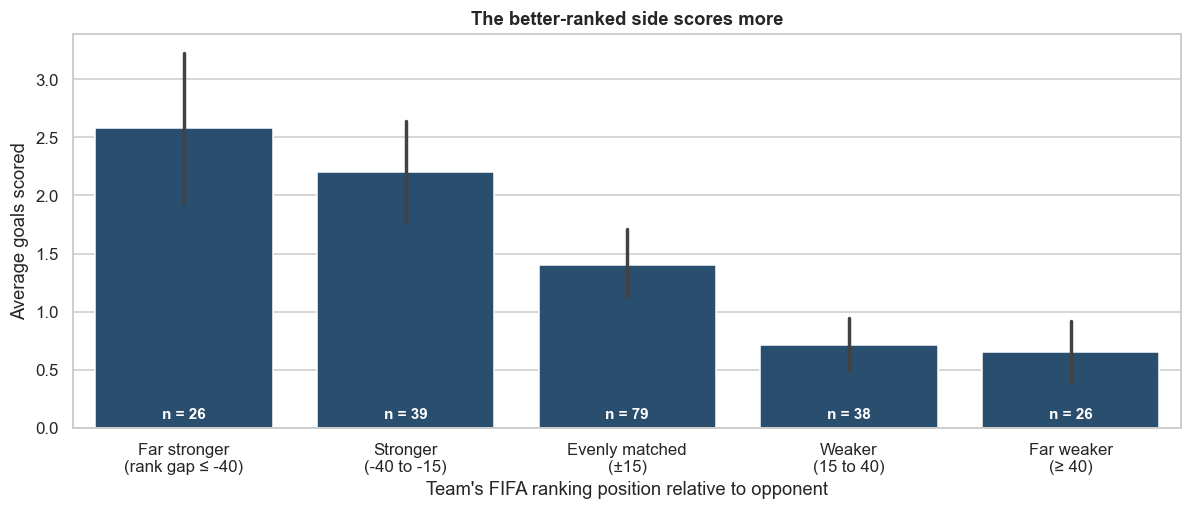

,mean,count
Band,,
Far stronger\n(rank gap ≤ -40),2.58,26
Stronger\n(-40 to -15),2.21,39
Evenly matched\n(±15),1.41,79
Weaker\n(15 to 40),0.71,38
Far weaker\n(≥ 40),0.65,26


In [9]:
bands = pd.cut(df["Rank_Diff"], [-100, -40, -15, 15, 40, 100],
               labels=["Far stronger\n(rank gap ≤ -40)", "Stronger\n(-40 to -15)", "Evenly matched\n(±15)", "Weaker\n(15 to 40)", "Far weaker\n(≥ 40)"])
band_tbl = df.assign(Band=bands).groupby("Band", observed=True)[TARGET].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.barplot(x=bands, y=df[TARGET], errorbar=("ci", 95), n_boot=2000, seed=SEED, color=C["main"], ax=ax)
for i, (m, c) in enumerate(zip(band_tbl["mean"], band_tbl["count"])):
    ax.text(i, 0.08, f"n = {c}", ha="center", color="white", fontsize=10, fontweight="bold")
ax.set(title="The better-ranked side scores more", xlabel="Team's FIFA ranking position relative to opponent", ylabel="Average goals scored")
plt.tight_layout(); plt.show()
display(band_tbl.round(2))

**Reading the ranking bands.** The effect is large and steady: teams ranked far above their opponent average about 2.6 goals, evenly matched sides about 1.4, and far weaker sides about 0.65. The drop between the last two bands is small, which matches the flattening seen above.

### 3.7 Tournament stage and team-level patterns

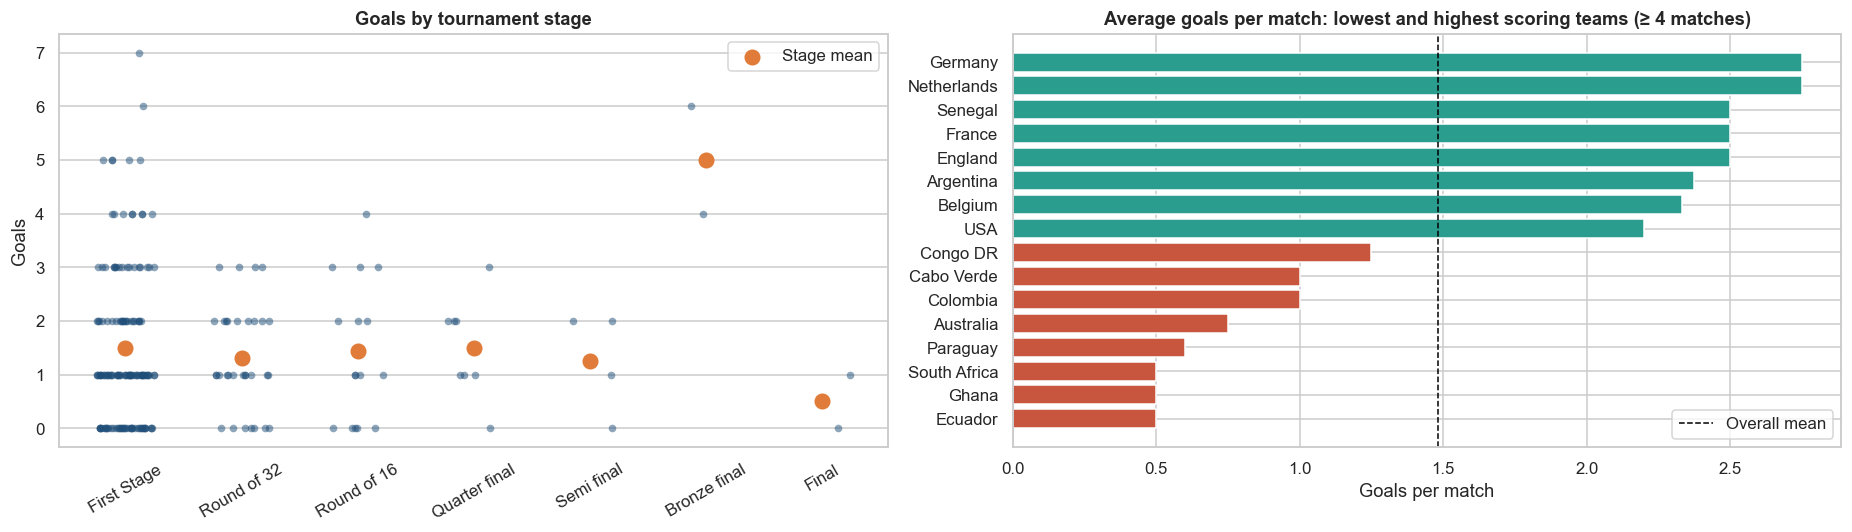

Kruskal-Wallis across 7 stages: H = 7.00, p = 0.320
Group vs knockout (Mann-Whitney): p = 0.706 | means 1.49 vs 1.45


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
sns.stripplot(data=df, x="Stage", y=TARGET, order=stage_order, jitter=.25, alpha=.5, color=C["main"], ax=ax[0])
means = df.groupby("Stage")[TARGET].mean().reindex(stage_order)
ax[0].scatter(range(len(stage_order)), means.values, color=C["accent"], s=90, zorder=5, label="Stage mean")
ax[0].set(title="Goals by tournament stage", xlabel=""); ax[0].tick_params(axis="x", rotation=30); ax[0].legend()

team = df.groupby("Team_Name")[TARGET].agg(["mean", "count"])
team = team[team["count"] >= 4].sort_values("mean")
show = pd.concat([team.head(8), team.tail(8)])
ax[1].barh(show.index, show["mean"], color=[C["bad"]] * 8 + [C["good"]] * 8)
ax[1].axvline(df[TARGET].mean(), color="black", ls="--", lw=1, label="Overall mean")
ax[1].set(title="Average goals per match: lowest and highest scoring teams (≥ 4 matches)", xlabel="Goals per match"); ax[1].legend()
plt.tight_layout(); plt.show()

ko = df["Stage"] != "First Stage"
kw = stats.kruskal(*[g[TARGET].values for _, g in df.groupby("Stage")])
mw = stats.mannwhitneyu(df.loc[~ko, TARGET], df.loc[ko, TARGET])
print(f"Kruskal-Wallis across 7 stages: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}")
print(f"Group vs knockout (Mann-Whitney): p = {mw.pvalue:.3f} | means {df.loc[~ko, TARGET].mean():.2f} vs {df.loc[ko, TARGET].mean():.2f}")

**Reading stage and team patterns.** Goals per team are almost identical in the group stage and the knockouts (1.49 vs 1.45; Mann-Whitney p = 0.71; Kruskal-Wallis across all seven stages p = 0.32), so tournament stage carries no detectable signal. Team averages vary widely (from about 0.5 to 2.75 goals per match), which is the kind of variation the ranking and pedigree variables should capture.

### 3.8 Inferential EDA: which relationships are statistically supported?
Pearson (linear) and Spearman (rank-based, robust to outliers and non-normality) tests are run for every feature against goals. p-values are adjusted for running 8 tests at once (Holm). Treat them as indicative, since the two rows of a match are related.

In [11]:
rows = []
for col in BASE:
    pr, pp = stats.pearsonr(df[col], df[TARGET])
    sr, sp = stats.spearmanr(df[col], df[TARGET])
    rows.append([col, pr, pp, sr, sp])
inf = pd.DataFrame(rows, columns=["Feature", "Pearson r", "p (Pearson)", "Spearman rho", "p (Spearman)"]).set_index("Feature")
inf["p (Pearson, Holm)"] = multipletests(inf["p (Pearson)"], method="holm")[1]
inf["Significant at 5%"] = np.where(inf["p (Pearson, Holm)"] < 0.05, "Yes", "No")
display(inf.sort_values("Pearson r", key=abs, ascending=False).round(4))

,Pearson r,p (Pearson),Spearman rho,p (Spearman),"p (Pearson, Holm)",Significant at 5%
Feature,,,,,,
Rank_Diff,-0.4763,0.0000,-0.4914,0.0000,0.0000,Yes
KO_Apps,0.3651,0.0000,0.3788,0.0000,0.0000,Yes
Opp_GK_Saves3,0.1734,0.0123,0.1890,0.0063,0.0736,No
Corners_pg3,0.1598,0.0212,0.1845,0.0077,0.1058,No
SOT_pg3,0.1515,0.0289,0.1699,0.0142,0.1158,No
Goals_pg3,0.1313,0.0588,0.1572,0.0233,0.1763,No
Age,-0.1030,0.1389,-0.0713,0.3060,0.2778,No
Strikers_Bench,-0.0112,0.8728,-0.0225,0.7472,0.8728,No


**Reading the tests.** After Holm correction only `Rank_Diff` and `KO_Apps` have individually significant linear relationships with goals; the other six do not clear the 5% threshold on their own. The Spearman results agree with Pearson, so the conclusions are not driven by outliers.

### 3.9 Multicollinearity check (VIF)
The Variance Inflation Factor shows how much each feature can be predicted from the others. Values above roughly 5 are a warning; above 10 is serious. This is the formal version of the "derived variable" concern: if one column were an exact formula of others, its VIF would be infinite.

In [12]:
def vif_table(frame, cols):
    X = sm.add_constant(frame[cols])
    out = pd.DataFrame({"Feature": cols, "VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(cols))]})
    return out.set_index("Feature")

vif_base = vif_table(df, BASE)
display(vif_base.round(2))

,VIF
Feature,
Age,1.09
Goals_pg3,2.81
SOT_pg3,5.02
Strikers_Bench,1.08
Rank_Diff,1.49
Corners_pg3,1.82
KO_Apps,1.85
Opp_GK_Saves3,2.49


**Reading the VIFs.** All are below 10, but `SOT_pg3` sits at about 5, the borderline level, reflecting its overlap with goals, corners and goalkeeper saves. The original eight variables are not redundant enough to break a regression, though shots on target is the one to watch.

### 3.10 EDA conclusions that drive the modelling plan

The findings above lead to the following decisions:

- **Signal is moderate.** `Rank_Diff` and `KO_Apps` carry most of the signal; several recent-form variables are weak on their own. We should expect a modest R², and say so honestly rather than chase an inflated one.
- **Rows are paired.** Validation must be **grouped by match**.
- **Counts, mild skew, some non-linearity in the ranking gap.** We test a transformation of `Rank_Diff` and a transformed target, and check residual diagnostics.
- **The opponent's strength is missing from the feature set.** Each row only describes the team itself plus the ranking gap. Because every match has a mirror row, the *opponent's* pre-match form can be attached to each row. This is the main feature-engineering idea tested in Step 8.
- **VIFs are low**, so the original 8 variables are not redundant with each other. We must be careful when engineering features not to create exact linear dependencies (for example a difference column together with both of its components).

## Step 4 — Validation design (decided before any modelling)

A trustworthy evaluation needs a strict separation between *choosing* a model and *judging* it.

1. **Locked hold-out test set.** 20% of *matches* (not rows) are set aside using a grouped split. They are not touched until the final model is chosen.
2. **Repeated, grouped K-fold cross-validation on the training matches** for every comparison, tuning and feature-selection decision. Grouping keeps both rows of a match in the same fold; repeating with different shuffles reduces the luck of any single split.
3. **Nested tuning.** When a model has hyperparameters (Ridge, Lasso, etc.), tuning happens *inside* each training fold so the CV score is not optimistic.
4. **Metrics.** RMSE (main, in goals), MAE, and R². Metrics are computed on pooled out-of-fold predictions for each repeat.

In [13]:
def group_kfold(k, seed):
    # shuffled grouped K-fold (needs scikit-learn >= 1.6; falls back to the unshuffled version)
    try:
        return GroupKFold(n_splits=k, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=k)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def fit_model(model, X, y, groups):
    # GridSearchCV and the nested selector need the match groups for their inner split
    m = clone(model)
    if isinstance(m, GridSearchCV) or getattr(m, "needs_groups", False):
        m.fit(X, y, groups=groups)
    else:
        m.fit(X, y)
    return m

def evaluate(model, X, y, groups, n_repeats=6, k=5, seed=100):
    # repeated grouped CV; returns per-repeat metrics and the out-of-fold prediction averaged over repeats
    rows, oof_all = [], np.zeros((n_repeats, len(y)))
    for r in range(n_repeats):
        for tr, va in group_kfold(k, seed + r).split(X, y, groups):
            m = fit_model(model, X.iloc[tr], y.iloc[tr], groups.iloc[tr])
            oof_all[r, va] = m.predict(X.iloc[va])
        rows.append({"repeat": r, "R2": r2_score(y, oof_all[r]), "RMSE": rmse(y, oof_all[r]), "MAE": mean_absolute_error(y, oof_all[r])})
    return pd.DataFrame(rows), oof_all.mean(axis=0)

def summarise(res):
    return pd.Series({"RMSE": res["RMSE"].mean(), "RMSE sd": res["RMSE"].std(), "MAE": res["MAE"].mean(), "R2": res["R2"].mean()})

# grouped hold-out split: 80% / 20% of matches
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, groups=df["Match_ID"]))
train = df.iloc[train_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)
print(f"Training: {len(train)} rows / {train['Match_ID'].nunique()} matches")
print(f"Hold-out test (locked): {len(test)} rows / {test['Match_ID'].nunique()} matches")
print("Overlap of matches between train and test:", len(set(train['Match_ID']) & set(test['Match_ID'])))

y_tr, g_tr = train[TARGET], train["Match_ID"]

Training: 166 rows / 83 matches
Hold-out test (locked): 42 rows / 21 matches
Overlap of matches between train and test: 0


## Step 5 — Baselines: what does "no skill" look like?

Any model has to beat simple reference points, otherwise it is not adding value:

- **Mean-only:** always predict the average number of goals.
- **Ranking gap only:** a one-variable regression on `Rank_Diff`.
- **OLS on the 8 original variables:** the model implied by the dataset as designed.

In [14]:
ols = lambda: make_pipeline(StandardScaler(), LinearRegression())

baselines = {
    "Mean-only (no features)": (DummyRegressor(), BASE),
    "Rank_Diff only": (ols(), ["Rank_Diff"]),
    "OLS - 8 original features": (ols(), BASE),
}
base_rows, base_runs = {}, {}
for name, (mdl, feats) in baselines.items():
    res, _ = evaluate(mdl, train[feats], y_tr, g_tr, n_repeats=10)
    base_runs[name] = res
    base_rows[name] = summarise(res)
baseline_tbl = pd.DataFrame(base_rows).T
display(baseline_tbl.round(3))

,RMSE,RMSE sd,MAE,R2
Mean-only (no features),1.390,0.007,1.112,-0.017
Rank_Diff only,1.241,0.009,0.949,0.190
OLS - 8 original features,1.245,0.014,0.961,0.184


**What the baselines say.** Predicting the mean gives an RMSE of about 1.39 goals. A regression on `Rank_Diff` alone cuts that to about 1.24 (R² ≈ 0.19). Using all eight original variables gives essentially the *same* error (1.245, R² ≈ 0.18). In other words, **the seven other variables add no out-of-sample accuracy beyond the ranking gap**. That is the key challenge for the rest of the notebook: find extra information that genuinely helps, and avoid adding variables that only add noise.

## Step 6 — The baseline linear regression in detail (statsmodels)

`scikit-learn` is used for prediction and validation. `statsmodels` is used here because it provides what an assessor looks for in a regression analysis: coefficients, confidence intervals, p-values and diagnostics.

Because the two rows of a match are related, standard errors are computed **clustered by match**. They are more honest than the default ones.

In [15]:
Xc = sm.add_constant(train[BASE])
ols_plain = sm.OLS(y_tr, Xc).fit()
cluster_ids = pd.factorize(train["Match_ID"])[0]
ols_clust = sm.OLS(y_tr, Xc).fit(cov_type="cluster", cov_kwds={"groups": cluster_ids})

print(ols_plain.summary())
print()
print(f"Training R2 = {ols_plain.rsquared:.3f} | Adjusted R2 = {ols_plain.rsquared_adj:.3f} | F-test p = {ols_plain.f_pvalue:.2e}")

coef = pd.DataFrame({
    "Coefficient": ols_clust.params,
    "SE (classical)": ols_plain.bse,
    "SE (clustered)": ols_clust.bse,
    "p (clustered)": ols_clust.pvalues,
    "CI low": ols_clust.conf_int()[0],
    "CI high": ols_clust.conf_int()[1],
})
display(coef.round(4))

                            OLS Regression Results                            
Dep. Variable:                  Goals   R-squared:                       0.280
Model:                            OLS   Adj. R-squared:                  0.244
Method:                 Least Squares   F-statistic:                     7.650
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.27e-08
Time:                        13:51:06   Log-Likelihood:                -261.50
No. Observations:                 166   AIC:                             541.0
Df Residuals:                     157   BIC:                             569.0
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              4.6509      2.580      1.

,Coefficient,SE (classical),SE (clustered),p (clustered),CI low,CI high
const,4.6509,2.5801,2.4316,0.0558,-0.1149,9.4168
Age,-0.1206,0.0895,0.0817,0.1399,-0.2806,0.0395
Goals_pg3,-0.0858,0.1791,0.1619,0.5962,-0.4032,0.2316
SOT_pg3,-0.0407,0.1110,0.1065,0.7026,-0.2493,0.1680
Strikers_Bench,0.1096,0.0956,0.1020,0.2828,-0.0904,0.3095
Rank_Diff,-0.0153,0.0032,0.0033,0.0000,-0.0218,-0.0088
Corners_pg3,-0.0475,0.0576,0.0566,0.4020,-0.1585,0.0636
KO_Apps,0.1061,0.0404,0.0450,0.0183,0.0179,0.1942
Opp_GK_Saves3,0.0595,0.1283,0.1206,0.6214,-0.1768,0.2958


### Standardised effects: which variables matter most?
Raw coefficients cannot be compared because the variables use different units. Standardising each variable (mean 0, SD 1) turns each coefficient into *"extra goals for a one-standard-deviation increase"*, which makes effect sizes comparable.

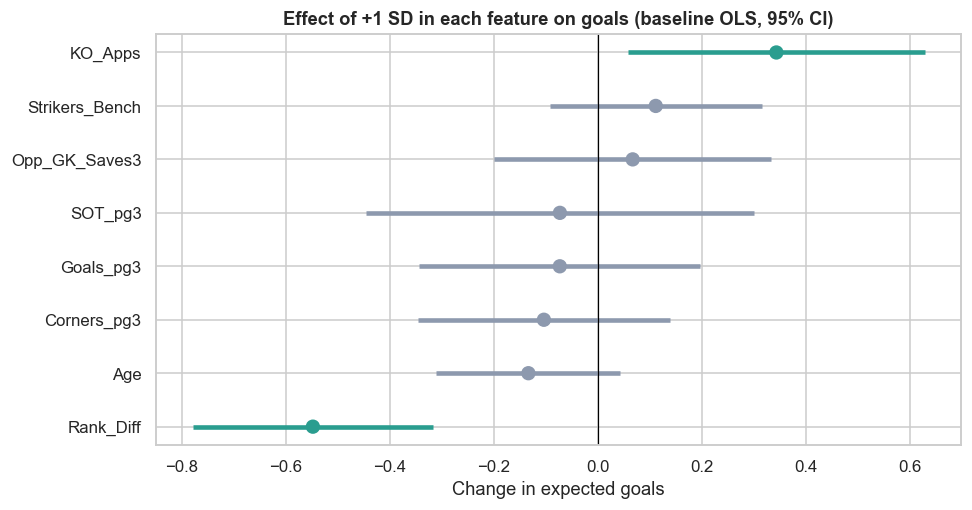

Green = statistically significant at 5% (clustered SE); grey = not significant.


In [16]:
Z = (train[BASE] - train[BASE].mean()) / train[BASE].std()
z_fit = sm.OLS(y_tr, sm.add_constant(Z)).fit(cov_type="cluster", cov_kwds={"groups": cluster_ids})
zc = pd.DataFrame({"effect": z_fit.params, "lo": z_fit.conf_int()[0], "hi": z_fit.conf_int()[1], "p": z_fit.pvalues}).drop("const").sort_values("effect")

fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [C["good"] if p < .05 else C["grey"] for p in zc["p"]]
ax.hlines(zc.index, zc["lo"], zc["hi"], color=colors, lw=3)
ax.scatter(zc["effect"], zc.index, color=colors, s=70, zorder=3)
ax.axvline(0, color="black", lw=.8)
ax.set(title="Effect of +1 SD in each feature on goals (baseline OLS, 95% CI)", xlabel="Change in expected goals")
plt.tight_layout(); plt.show()
print("Green = statistically significant at 5% (clustered SE); grey = not significant.")

**Reading the baseline regression.** The model explains about 28% of the variance in the training data (adjusted R² ≈ 0.24) and is significant overall (F-test p ≈ 1e-8). Only two variables are individually significant with match-clustered errors:

- **`Rank_Diff`** (-0.015 per ranking place, p < 0.001): a team ranked 10 places better is expected to score about 0.15 more goals.
- **`KO_Apps`** (+0.11 per knockout appearance, p ≈ 0.02): tournament pedigree adds goals beyond what ranking explains.

`Goals_pg3` and `SOT_pg3` have *negative* coefficients even though both correlate positively with goals on their own. That is a collinearity effect, not a real negative relationship: the two overlap strongly with each other (r = 0.72) and with ranking and pedigree, so once those are in the model the leftover signal is noise. Coefficients of correlated variables should not be read one at a time. The clustered standard errors differ only slightly from the classical ones, so the within-match dependence is not distorting the main conclusions.

## Step 7 — Do the linear regression assumptions hold?

A regression is only trustworthy if its assumptions are reasonable. The panels below test each one:

| Assumption | Check |
|---|---|
| Linearity | Residuals vs fitted values (no curve) |
| Normal errors | Q–Q plot, histogram, Shapiro–Wilk test |
| Constant variance | Scale–location plot, Breusch–Pagan test |
| No influential points | Cook's distance and leverage |
| No multicollinearity | VIF (done in Step 3.9) |
| Independent errors | Correlation of residuals within the same match |

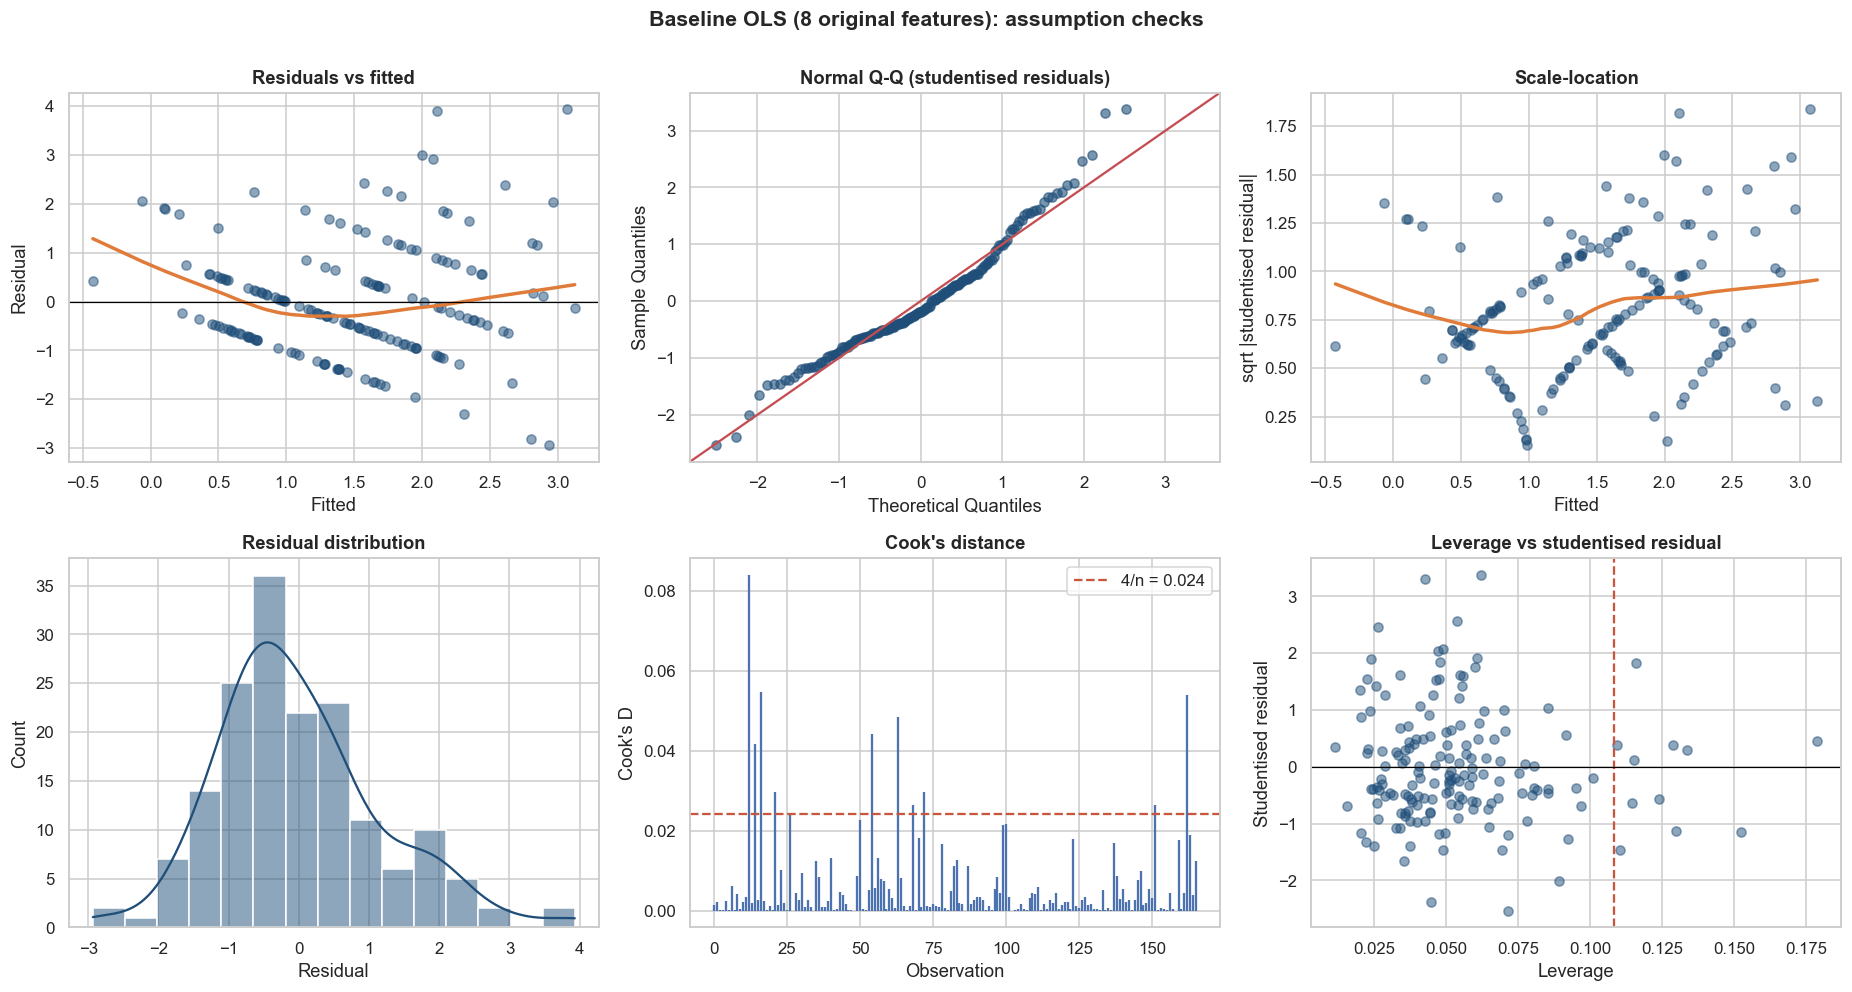

,value
Breusch-Pagan p (constant variance),0.0509
Shapiro-Wilk p (normal residuals),0.0003
Residual skew,0.6958
Within-match residual correlation,0.3190
Within-match corr p-value,0.0033
Cook's D above 4/n (count),11.0000
Max Cook's D,0.0841
Condition number,989.6110


In [17]:
def ols_diagnostics(res, groups, title=""):
    infl = res.get_influence()
    fitted, resid = np.asarray(res.fittedvalues), np.asarray(res.resid)
    stud, lev, cooks = infl.resid_studentized_internal, infl.hat_matrix_diag, infl.cooks_distance[0]
    n_obs, p = int(res.nobs), len(res.params)

    fig, ax = plt.subplots(2, 3, figsize=(17, 9))
    ax[0, 0].scatter(fitted, resid, alpha=.5, color=C["main"])
    sns.regplot(x=fitted, y=resid, lowess=True, scatter=False, line_kws={"color": C["accent"]}, ax=ax[0, 0])
    ax[0, 0].axhline(0, color="black", lw=.8); ax[0, 0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")

    sm.qqplot(stud, line="45", ax=ax[0, 1], markerfacecolor=C["main"], markeredgecolor=C["main"], alpha=.6)
    ax[0, 1].set_title("Normal Q-Q (studentised residuals)")

    ax[0, 2].scatter(fitted, np.sqrt(np.abs(stud)), alpha=.5, color=C["main"])
    sns.regplot(x=fitted, y=np.sqrt(np.abs(stud)), lowess=True, scatter=False, line_kws={"color": C["accent"]}, ax=ax[0, 2])
    ax[0, 2].set(title="Scale-location", xlabel="Fitted", ylabel="sqrt |studentised residual|")

    sns.histplot(resid, kde=True, color=C["main"], ax=ax[1, 0]); ax[1, 0].set(title="Residual distribution", xlabel="Residual")

    ax[1, 1].stem(np.arange(n_obs), cooks, markerfmt=" ", basefmt=" ")
    thr = 4 / n_obs
    ax[1, 1].axhline(thr, color=C["bad"], ls="--", label=f"4/n = {thr:.3f}"); ax[1, 1].legend()
    ax[1, 1].set(title="Cook's distance", xlabel="Observation", ylabel="Cook's D")

    ax[1, 2].scatter(lev, stud, alpha=.5, color=C["main"])
    ax[1, 2].axvline(2 * p / n_obs, color=C["bad"], ls="--"); ax[1, 2].axhline(0, color="black", lw=.8)
    ax[1, 2].set(title="Leverage vs studentised residual", xlabel="Leverage", ylabel="Studentised residual")
    plt.suptitle(title, y=1.0, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

    bp = het_breuschpagan(resid, res.model.exog)
    sw = stats.shapiro(resid)
    # residual correlation between the two teams of the same match
    tmp = pd.DataFrame({"g": np.asarray(groups), "r": resid})
    pair = tmp.groupby("g")["r"].apply(list)
    pair = pair[pair.apply(len) == 2]
    a = np.array([v[0] for v in pair]); b = np.array([v[1] for v in pair])
    rc, rp = stats.pearsonr(a, b)
    out = pd.Series({
        "Breusch-Pagan p (constant variance)": bp[1],
        "Shapiro-Wilk p (normal residuals)": sw.pvalue,
        "Residual skew": stats.skew(resid),
        "Within-match residual correlation": rc,
        "Within-match corr p-value": rp,
        "Cook's D above 4/n (count)": int((cooks > thr).sum()),
        "Max Cook's D": cooks.max(),
        "Condition number": res.condition_number,
    })
    return out

diag_base = ols_diagnostics(ols_plain, train["Match_ID"], "Baseline OLS (8 original features): assumption checks")
display(diag_base.round(4).to_frame("value"))

**Verdict on the assumptions (baseline model).**

- **Linearity:** broadly acceptable, with a mild curve at the low end of the fitted values (the model under-predicts the lowest-scoring teams slightly). The parallel diagonal bands in the plots are normal for a target made of whole numbers.
- **Normality:** not met. The Q-Q plot departs in the upper tail and the Shapiro-Wilk test rejects normality (p ≈ 0.0003, residual skew ≈ 0.7). This is the signature of count data.
- **Constant variance:** borderline (Breusch-Pagan p ≈ 0.05). Spread tends to grow with the predicted mean.
- **Influence:** no single match dominates. 11 rows exceed the 4/n guideline, but the largest Cook's distance is only about 0.08 (a value near 1 would be a concern).
- **Independence:** *not* met in the strict sense. The residuals of the two teams in the same match are positively correlated (r ≈ 0.32, p ≈ 0.003), meaning some match-level factor such as tempo or openness raises or lowers both teams' goals. This is why validation is grouped by match and standard errors are clustered.

None of these problems invalidate the model for **prediction**, which is judged by cross-validation. They do mean classical p-values should be treated with caution, which is why the final interpretation uses a bootstrap instead.

### Partial regression plots
Each panel shows one feature's relationship with goals *after removing the effect of all the other features*. The slope of the line is exactly that feature's regression coefficient, so these plots show the unique contribution of each variable.

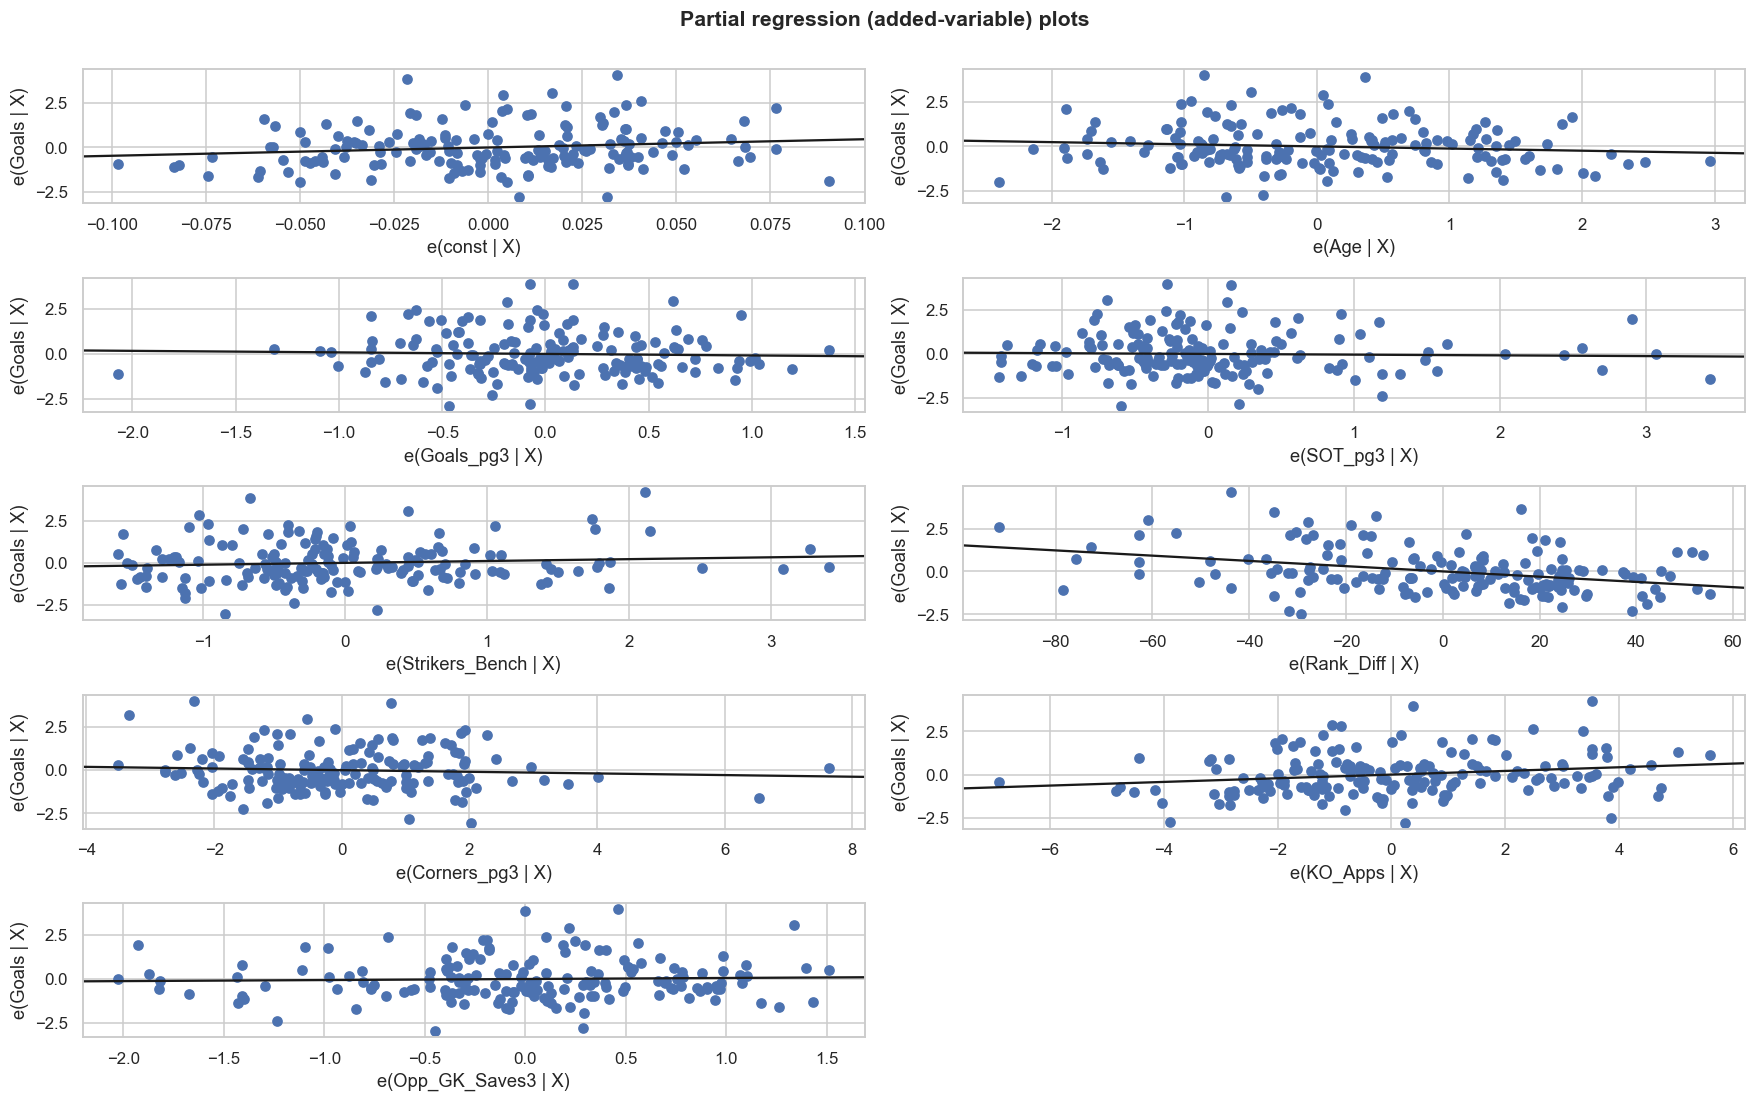

In [18]:
fig = plt.figure(figsize=(16, 10))
sm.graphics.plot_partregress_grid(ols_plain, fig=fig)
plt.suptitle("Partial regression (added-variable) plots", y=1.0, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Takeaway before feature engineering.** The partial regression plots confirm that, after accounting for everything else, only the ranking gap and knockout pedigree show a clear slope. The remaining signal must come from better-constructed features or better handling of noise, which is what Steps 8 to 10 explore.

## Step 8 — Feature engineering and data transformation (systematic experiments)

Each row currently describes only the team itself plus the ranking gap. Because every match has a mirror row, the **opponent's pre-match form** can be attached to each row. All engineered features below use only pre-match information.

| New feature | Idea |
|---|---|
| `Opp_Goals_pg3`, `Opp_SOT_pg3`, `Opp_Corners_pg3` | How dangerous the opponent has recently been (a stronger attacker also tends to mean a more open game) |
| `Own_GK_Saves3` | The team's *own* goalkeeper workload: saves per game, taken from the opponent row. High workload suggests a leaky defence |
| `Opp_KO_Apps`, `Opp_Age`, `Opp_Strikers` | Opponent's tournament pedigree, age and strikers |
| `Is_Knockout` | Group stage (0) vs knockout (1) |
| `Rank_ssqrt` | Signed square root of the ranking gap, which tests whether the effect flattens for very large gaps |
| `SOT_x_OppGK` | Interaction: a team's shot volume combined with the opposing goalkeeper's workload (centred) |
| `Shot_Conv` | Goals per shot on target, a finishing-efficiency ratio |
| `*_diff` columns | Team minus opponent versions of a variable |

**A caution from the earlier discussion:** the `*_diff` columns are exact linear combinations of a team column and an opponent column. They are tested only as a *replacement* design and are never placed in the same model as both of their components, because that would create perfect multicollinearity.

Centring statistics for the interaction term are computed from the **training split only**.

In [19]:
CENTRE = {"SOT_pg3": train["SOT_pg3"].mean(), "Opp_GK_Saves3": train["Opp_GK_Saves3"].mean()}

def add_features(frame):
    f = frame.copy()
    opp = frame[["Match_ID", "Team_Name", "Goals_pg3", "SOT_pg3", "Corners_pg3", "Opp_GK_Saves3", "KO_Apps", "Age", "Strikers_Bench"]].rename(columns={
        "Team_Name": "Opposition_Team_Name", "Goals_pg3": "Opp_Goals_pg3", "SOT_pg3": "Opp_SOT_pg3", "Corners_pg3": "Opp_Corners_pg3",
        "Opp_GK_Saves3": "Own_GK_Saves3", "KO_Apps": "Opp_KO_Apps", "Age": "Opp_Age", "Strikers_Bench": "Opp_Strikers"})
    f = f.merge(opp, on=["Match_ID", "Opposition_Team_Name"], how="left", validate="one_to_one")
    f["Is_Knockout"] = (f["Stage"] != "First Stage").astype(int)
    f["Rank_ssqrt"] = np.sign(f["Rank_Diff"]) * np.sqrt(f["Rank_Diff"].abs())
    f["SOT_x_OppGK"] = (f["SOT_pg3"] - CENTRE["SOT_pg3"]) * (f["Opp_GK_Saves3"] - CENTRE["Opp_GK_Saves3"])
    f["Shot_Conv"] = f["Goals_pg3"] / f["SOT_pg3"].clip(lower=0.33)
    f["Goals_diff"] = f["Goals_pg3"] - f["Opp_Goals_pg3"]
    f["SOT_diff"] = f["SOT_pg3"] - f["Opp_SOT_pg3"]
    f["Corners_diff"] = f["Corners_pg3"] - f["Opp_Corners_pg3"]
    f["KO_diff"] = f["KO_Apps"] - f["Opp_KO_Apps"]
    f["Age_diff"] = f["Age"] - f["Opp_Age"]
    return f

fe_all = add_features(df)
assert fe_all.isna().sum().sum() == 0 and len(fe_all) == len(df)
train_fe = add_features(train)
test_fe = add_features(test)

OPP_ATTACK = ["Opp_Goals_pg3", "Opp_SOT_pg3", "Own_GK_Saves3"]
OPP_ALL = ["Opp_Goals_pg3", "Opp_SOT_pg3", "Opp_Corners_pg3", "Own_GK_Saves3", "Opp_KO_Apps", "Opp_Age", "Opp_Strikers"]
POOL = BASE + OPP_ALL + ["Is_Knockout", "Rank_ssqrt", "SOT_x_OppGK"]
print(f"Candidate feature pool: {len(POOL)} features (8 original + {len(POOL) - 8} engineered)")
display(train_fe[["Team_Name", "Opposition_Team_Name"] + OPP_ATTACK + ["Is_Knockout", "Rank_ssqrt", "SOT_x_OppGK"]].head())

# the pool contains overlapping features (e.g. Rank_Diff and Rank_ssqrt), so check redundancy again
vif_pool = vif_table(train_fe, POOL).sort_values("VIF", ascending=False)
display(vif_pool.round(1).head(8))

Candidate feature pool: 18 features (8 original + 10 engineered)


,Team_Name,Opposition_Team_Name,Opp_Goals_pg3,Opp_SOT_pg3,Own_GK_Saves3,Is_Knockout,Rank_ssqrt,SOT_x_OppGK
0,Mexico,South Africa,0.67,4.00,4.00,0,-6.782330,1.577092
1,South Africa,Mexico,2.67,6.00,4.33,0,6.782330,-0.921079
2,Korea Republic,Czechia,2.33,4.00,2.67,0,-3.872983,1.203258
3,Czechia,Korea Republic,2.00,6.00,4.00,0,3.872983,0.232255
4,Canada,Bosnia and Herzegovina,0.67,6.33,4.00,0,-5.830952,-0.340076


,VIF
Feature,
Rank_ssqrt,18.9
Rank_Diff,16.0
SOT_pg3,4.7
Opp_SOT_pg3,4.7
Goals_pg3,2.7
Opp_Goals_pg3,2.7
Opp_GK_Saves3,2.6
Own_GK_Saves3,2.5


**Redundancy in the pool.** Several VIFs are now high, as expected: `Rank_Diff` and its square-root version describe the same quantity, and shot volume, goals and the interaction term overlap. None is an *exact* formula (so nothing breaks mathematically), but plain OLS on the whole pool will have unstable coefficients. This is the main reason regularised models are tested in Step 9.

### 8.1 Experiments
Every experiment changes **one thing** relative to the baseline and is scored with the same repeated, grouped CV (same splits), so the comparison is fair. "Better in x/10 repeats" counts how often the experiment beat the baseline on identical splits.

,Features,RMSE,RMSE sd,MAE,R2,Delta RMSE vs E0,Better than E0 in (of 10)
Experiment,,,,,,,
E0 Baseline: 8 original features,8,1.2454,0.0145,0.9609,0.1836,0.0000,0
E1 + knockout flag,9,1.2562,0.0130,0.9690,0.1694,0.0108,0
E2 + opponent attack & own GK workload,11,1.2289,0.0225,0.9496,0.2049,-0.0165,10
E3 + all opponent features,15,1.2618,0.0205,0.9732,0.1618,0.0164,1
E4 Team-minus-opponent design (differences),8,1.2462,0.0167,0.9448,0.1825,0.0008,6
E5 Rank gap as signed square root,8,1.2384,0.0150,0.9506,0.1928,-0.0071,10
E6 + shot-volume x GK-workload interaction,9,1.2349,0.0177,0.9491,0.1973,-0.0106,9
E7 + shot conversion ratio,9,1.2508,0.0156,0.9658,0.1765,0.0054,0
E8 E2 with sqrt-transformed target,11,1.2645,0.0218,0.9371,0.1582,0.0191,0


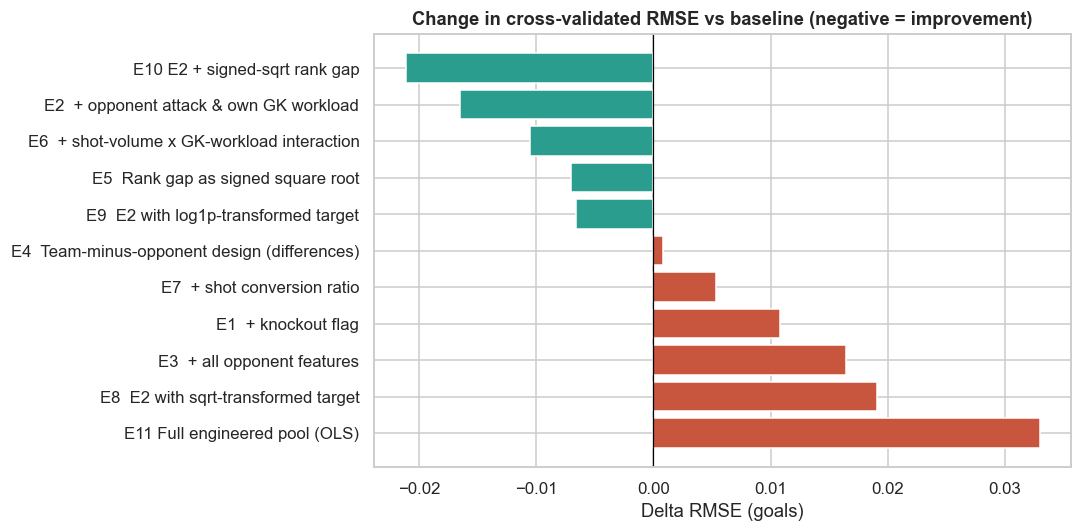

In [20]:
def ols_pipe(target=None):
    core = make_pipeline(StandardScaler(), LinearRegression())
    if target == "sqrt":
        return TransformedTargetRegressor(regressor=core, func=np.sqrt, inverse_func=np.square)
    if target == "log1p":
        return TransformedTargetRegressor(regressor=core, func=np.log1p, inverse_func=np.expm1)
    return core

SWAP_RANK = [c for c in BASE if c != "Rank_Diff"] + ["Rank_ssqrt"]
EXPERIMENTS = {
    "E0  Baseline: 8 original features": dict(features=BASE),
    "E1  + knockout flag": dict(features=BASE + ["Is_Knockout"]),
    "E2  + opponent attack & own GK workload": dict(features=BASE + OPP_ATTACK),
    "E3  + all opponent features": dict(features=BASE + OPP_ALL),
    "E4  Team-minus-opponent design (differences)": dict(features=["Rank_Diff", "Goals_diff", "SOT_diff", "Corners_diff", "KO_diff", "Age_diff", "Opp_GK_Saves3", "Own_GK_Saves3"]),
    "E5  Rank gap as signed square root": dict(features=SWAP_RANK),
    "E6  + shot-volume x GK-workload interaction": dict(features=BASE + ["SOT_x_OppGK"]),
    "E7  + shot conversion ratio": dict(features=BASE + ["Shot_Conv"]),
    "E8  E2 with sqrt-transformed target": dict(features=BASE + OPP_ATTACK, target="sqrt"),
    "E9  E2 with log1p-transformed target": dict(features=BASE + OPP_ATTACK, target="log1p"),
    "E10 E2 + signed-sqrt rank gap": dict(features=[c for c in BASE + OPP_ATTACK if c != "Rank_Diff"] + ["Rank_ssqrt"]),
    "E11 Full engineered pool (OLS)": dict(features=POOL),
}

exp_runs = {}
for name, spec in EXPERIMENTS.items():
    exp_runs[name], _ = evaluate(ols_pipe(spec.get("target")), train_fe[spec["features"]], y_tr, g_tr, n_repeats=10)

ref = exp_runs["E0  Baseline: 8 original features"]
rows = []
for name, res in exp_runs.items():
    rows.append({
        "Experiment": name, "Features": len(EXPERIMENTS[name]["features"]),
        "RMSE": res["RMSE"].mean(), "RMSE sd": res["RMSE"].std(), "MAE": res["MAE"].mean(), "R2": res["R2"].mean(),
        "Delta RMSE vs E0": res["RMSE"].mean() - ref["RMSE"].mean(),
        "Better than E0 in (of 10)": int((res["RMSE"].values < ref["RMSE"].values).sum()),
    })
exp_tbl = pd.DataFrame(rows).set_index("Experiment")
display(exp_tbl.round(4))

plot_tbl = exp_tbl.drop(index="E0  Baseline: 8 original features").sort_values("Delta RMSE vs E0", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(plot_tbl.index, plot_tbl["Delta RMSE vs E0"], color=[C["good"] if v < 0 else C["bad"] for v in plot_tbl["Delta RMSE vs E0"]])
ax.axvline(0, color="black", lw=.8)
ax.set(title="Change in cross-validated RMSE vs baseline (negative = improvement)", xlabel="Delta RMSE (goals)")
plt.tight_layout(); plt.show()

**What the experiments show** (training CV, 10 repeats, RMSE in goals; lower is better).

- **Changes that helped:** adding the opponent's attack and the team's own goalkeeper workload (E2) lowered RMSE by about 0.017; using the signed square root of the ranking gap (E5) by about 0.007; the shot-volume × goalkeeper-workload interaction (E6) by about 0.011. Combining the first two ideas (E10) gave the best result, roughly 0.021 below the baseline. A log-transformed target (E9) improved MAE noticeably (0.92 vs 0.96) with a small RMSE gain.
- **Changes that did not help:** the knockout flag (E1), all opponent features at once (E3), the shot-conversion ratio (E7), a square-root target (E8) and the difference design (E4, no change). Dropping everything into plain OLS (E11) was the worst result, about 0.033 *worse* than the baseline.
- **Lesson:** each improvement is small, and with only about 160 training rows, piling on features makes ordinary least squares worse because the extra coefficients add more noise than signal. Smarter selection or shrinkage is needed.

### 8.2 Feature selection: forward selection with a stability rule
Adding every feature is not always best. With about 160 training rows, extra weak features add noise. Forward selection adds, at each step, the feature that most reduces cross-validated RMSE. The final subset is the **smallest set within one standard deviation of the best score** (the "one-standard-error rule"), which prefers simpler models when extra features add little.

Selection uses different CV shuffles (seed 500) from the later model comparison (seed 100) to limit optimism. The locked test set is the final honest check.

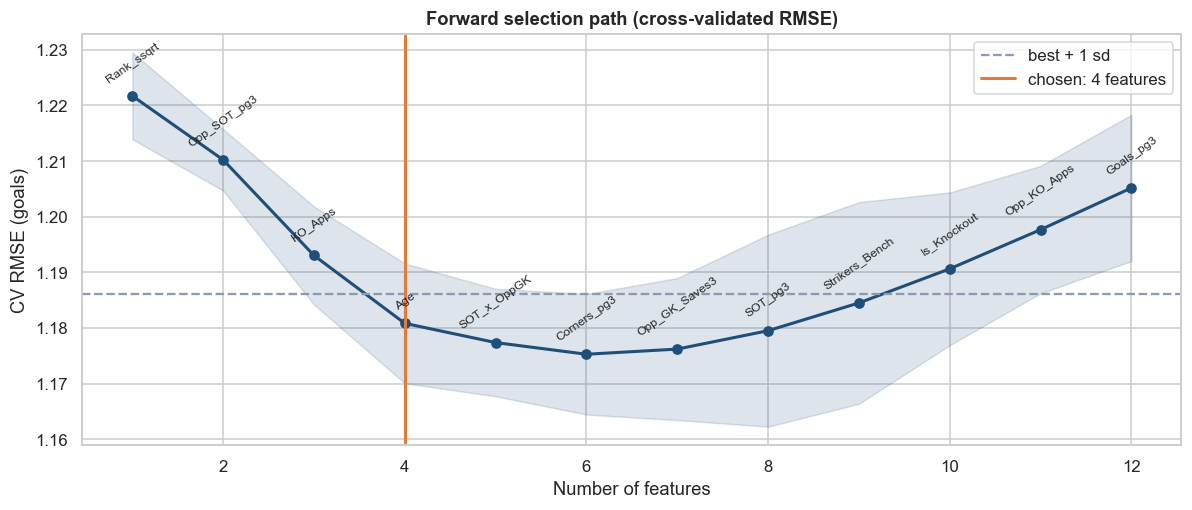

,Step,Feature added,CV RMSE,sd
0,1,Rank_ssqrt,1.2217,0.0078
1,2,Opp_SOT_pg3,1.2102,0.0055
2,3,KO_Apps,1.1930,0.0088
3,4,Age,1.1808,0.0108
4,5,SOT_x_OppGK,1.1774,0.0097
5,6,Corners_pg3,1.1753,0.0108
6,7,Opp_GK_Saves3,1.1762,0.0128
7,8,SOT_pg3,1.1795,0.0173
8,9,Strikers_Bench,1.1845,0.0181
9,10,Is_Knockout,1.1906,0.0137


Selected features: ['Rank_ssqrt', 'Opp_SOT_pg3', 'KO_Apps', 'Age']


In [21]:
selected, remaining, path = [], list(POOL), []
for step in range(1, 13):
    scores = {}
    for f in remaining:
        res, _ = evaluate(ols_pipe(), train_fe[selected + [f]], y_tr, g_tr, n_repeats=4, seed=500)
        scores[f] = (res["RMSE"].mean(), res["RMSE"].std())
    best = min(scores, key=lambda k: scores[k][0])
    selected.append(best); remaining.remove(best)
    path.append({"Step": step, "Feature added": best, "CV RMSE": scores[best][0], "sd": scores[best][1]})
path_df = pd.DataFrame(path)

i_min = path_df["CV RMSE"].idxmin()
threshold = path_df.loc[i_min, "CV RMSE"] + path_df.loc[i_min, "sd"]
k_star = int(path_df.loc[path_df["CV RMSE"] <= threshold, "Step"].min())
SELECTED = selected[:k_star]

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(path_df["Step"], path_df["CV RMSE"], "o-", color=C["main"], lw=2)
ax.fill_between(path_df["Step"], path_df["CV RMSE"] - path_df["sd"], path_df["CV RMSE"] + path_df["sd"], color=C["main"], alpha=.15)
ax.axhline(threshold, color=C["grey"], ls="--", label="best + 1 sd")
ax.axvline(k_star, color=C["accent"], lw=2, label=f"chosen: {k_star} features")
for _, r in path_df.iterrows():
    ax.annotate(r["Feature added"], (r["Step"], r["CV RMSE"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, rotation=35)
ax.set(title="Forward selection path (cross-validated RMSE)", xlabel="Number of features", ylabel="CV RMSE (goals)"); ax.legend()
plt.tight_layout(); plt.show()

display(path_df.round(4))
print("Selected features:", SELECTED)

**Reading the path.** The cross-validated error falls quickly as the first few features enter, bottoms out at roughly 5–7 features, then rises as noise features are added, a textbook picture of overfitting. The one-standard-error rule picks **4 features** (`Rank_ssqrt`, `Opp_SOT_pg3`, `KO_Apps`, `Age`).

**Caution.** The error shown here is *optimistic*: the same data both chooses the features and scores them. Step 9 measures how large that optimism is.

## Step 9 — Regularisation, tuning and competing algorithms

Several candidates are compared under **identical** repeated, grouped CV splits. Models with hyperparameters are tuned *inside* each training fold (nested CV), so the reported score is honest.

| Family | Models | Why included |
|---|---|---|
| Linear regression | OLS (8 original), OLS (all engineered), OLS with forward selection | The required technique, at three feature-set sizes |
| Regularised linear | Ridge, Lasso, ElasticNet | Shrink noisy coefficients; Lasso also removes features |
| Count model | Poisson regression | Goals are counts, so a log-link GLM is the principled alternative |
| Non-linear benchmarks | Random Forest, Gradient Boosting | Test whether non-linearity or interactions are being missed |
| Reference | Mean-only | The "no skill" floor |

The tree models are deliberately constrained (shallow, large leaves) because there are only about 160 training rows.

**A fairness point about feature selection.** The subset found in Step 8.2 was chosen using the same training matches that cross-validation scores, so scoring that fixed subset would be slightly optimistic. To compare it fairly, the selection itself is wrapped into an estimator (`ForwardSelectOLS`) that repeats the whole forward-selection search *inside every training fold*. Its score therefore includes the cost of choosing features from data.

In [22]:
from sklearn.base import BaseEstimator, RegressorMixin

class ForwardSelectOLS(BaseEstimator, RegressorMixin):
    # forward selection runs inside each training fold, so the CV score includes the cost of picking features
    needs_groups = True

    def __init__(self, max_features=7, inner_k=4, inner_repeats=3, seed=500):
        self.max_features = max_features
        self.inner_k = inner_k
        self.inner_repeats = inner_repeats
        self.seed = seed

    def _score(self, X, y, groups, cols):
        errs = []
        for r in range(self.inner_repeats):
            oof = np.zeros(len(y))
            for tr, va in group_kfold(self.inner_k, self.seed + r).split(X, y, groups):
                m = ols_pipe().fit(X.iloc[tr][cols], y.iloc[tr])
                oof[va] = m.predict(X.iloc[va][cols])
            errs.append(rmse(y, oof))
        return np.mean(errs), np.std(errs)

    def fit(self, X, y, groups):
        remaining, chosen, path = list(X.columns), [], []
        while remaining and len(chosen) < self.max_features:
            sc = {f: self._score(X, y, groups, chosen + [f]) for f in remaining}
            best = min(sc, key=lambda f: sc[f][0])
            chosen.append(best); remaining.remove(best); path.append(sc[best])
        means = np.array([p[0] for p in path]); sds = np.array([p[1] for p in path])
        i = int(means.argmin())
        k = int(np.where(means <= means[i] + sds[i])[0].min()) + 1
        self.selected_ = chosen[:k]
        self.model_ = ols_pipe().fit(X[self.selected_], y)
        return self

    def predict(self, X):
        return self.model_.predict(X[self.selected_])

inner = lambda k=5: GroupKFold(n_splits=k)

In [23]:
inner = lambda k=5: GroupKFold(n_splits=k)
scale = StandardScaler

registry = {
    "Mean-only": (DummyRegressor(), POOL),
    "OLS - 8 original": (ols_pipe(), BASE),
    "OLS - all engineered": (ols_pipe(), POOL),
    "OLS - forward selection": (ForwardSelectOLS(), POOL),
    "Ridge": (GridSearchCV(make_pipeline(scale(), Ridge()), {"ridge__alpha": np.logspace(-1, 3, 17)},
                           cv=inner(), scoring="neg_root_mean_squared_error"), POOL),
    "Lasso": (GridSearchCV(make_pipeline(scale(), Lasso(max_iter=20000)), {"lasso__alpha": np.logspace(-3, 0, 13)},
                           cv=inner(), scoring="neg_root_mean_squared_error"), POOL),
    "ElasticNet": (GridSearchCV(make_pipeline(scale(), ElasticNet(max_iter=20000)),
                                {"elasticnet__alpha": np.logspace(-3, 0, 7), "elasticnet__l1_ratio": [0.2, 0.5, 0.8]},
                                cv=inner(), scoring="neg_root_mean_squared_error"), POOL),
    "Poisson GLM": (GridSearchCV(make_pipeline(scale(), PoissonRegressor(max_iter=2000)), {"poissonregressor__alpha": np.logspace(-2, 2, 13)},
                                 cv=inner(), scoring="neg_root_mean_squared_error"), POOL),
    "Random Forest": (GridSearchCV(RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1),
                                   {"min_samples_leaf": [5, 12], "max_features": [0.4, 0.8]},
                                   cv=inner(3), scoring="neg_root_mean_squared_error"), POOL),
    "Gradient Boosting": (GridSearchCV(GradientBoostingRegressor(random_state=SEED, learning_rate=0.05, subsample=0.8),
                                       {"max_depth": [1, 2], "n_estimators": [50, 150]},
                                       cv=inner(3), scoring="neg_root_mean_squared_error"), POOL),
}

N_REP = 6
cmp_runs, cmp_oof = {}, {}
for name, (mdl, feats) in registry.items():
    cmp_runs[name], cmp_oof[name] = evaluate(mdl, train_fe[feats], y_tr, g_tr, n_repeats=N_REP)
    print(f"{name:22s} RMSE = {cmp_runs[name]['RMSE'].mean():.4f}")

cmp = pd.DataFrame({n: summarise(r) for n, r in cmp_runs.items()}).T
cmp.insert(0, "Features", [len(registry[n][1]) for n in cmp.index])
cmp = cmp.sort_values("RMSE")
display(cmp.round(4))

Mean-only              RMSE = 1.3915
OLS - 8 original       RMSE = 1.2455
OLS - all engineered   RMSE = 1.2766
OLS - forward selection RMSE = 1.2569
Ridge                  RMSE = 1.2254
Lasso                  RMSE = 1.2232
ElasticNet             RMSE = 1.2278
Poisson GLM            RMSE = 1.2262
Random Forest          RMSE = 1.2450
Gradient Boosting      RMSE = 1.2599


,Features,RMSE,RMSE sd,MAE,R2
Lasso,18,1.2232,0.0176,0.9289,0.2124
Ridge,18,1.2254,0.0203,0.9439,0.2095
Poisson GLM,18,1.2262,0.0229,0.9319,0.2084
ElasticNet,18,1.2278,0.0171,0.9354,0.2065
Random Forest,18,1.2450,0.0224,0.9337,0.1840
OLS - 8 original,8,1.2455,0.0180,0.9611,0.1834
OLS - forward selection,18,1.2569,0.0331,0.9546,0.1681
Gradient Boosting,18,1.2599,0.0548,0.9491,0.1633
OLS - all engineered,18,1.2766,0.0352,0.9800,0.1417
Mean-only,18,1.3915,0.0062,1.1125,-0.0191


In [24]:
# how optimistic is it to score a feature subset that was chosen on the same data?
naive_res, _ = evaluate(ols_pipe(), train_fe[SELECTED], y_tr, g_tr, n_repeats=N_REP)
optimism = pd.DataFrame({
    "CV RMSE": [naive_res["RMSE"].mean(), cmp.loc["OLS - forward selection", "RMSE"]],
}, index=["Fixed subset from Step 8.2 (selection and scoring share data)", "Selection repeated inside every fold (honest)"])
optimism["R2"] = [naive_res["R2"].mean(), cmp.loc["OLS - forward selection", "R2"]]
display(optimism.round(4))
print(f"Optimism from selecting features on the scoring data: {cmp.loc['OLS - forward selection', 'RMSE'] - naive_res['RMSE'].mean():.3f} goals of RMSE")

,CV RMSE,R2
Fixed subset from Step 8.2 (selection and scoring share data),1.1853,0.2605
Selection repeated inside every fold (honest),1.2569,0.1681


Optimism from selecting features on the scoring data: 0.072 goals of RMSE


C:\Users\DELL\AppData\Local\Temp\ipykernel_18020\1849196892.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=long, y="Model", x="RMSE", order=order, palette=fam, ax=ax[0], width=.55)


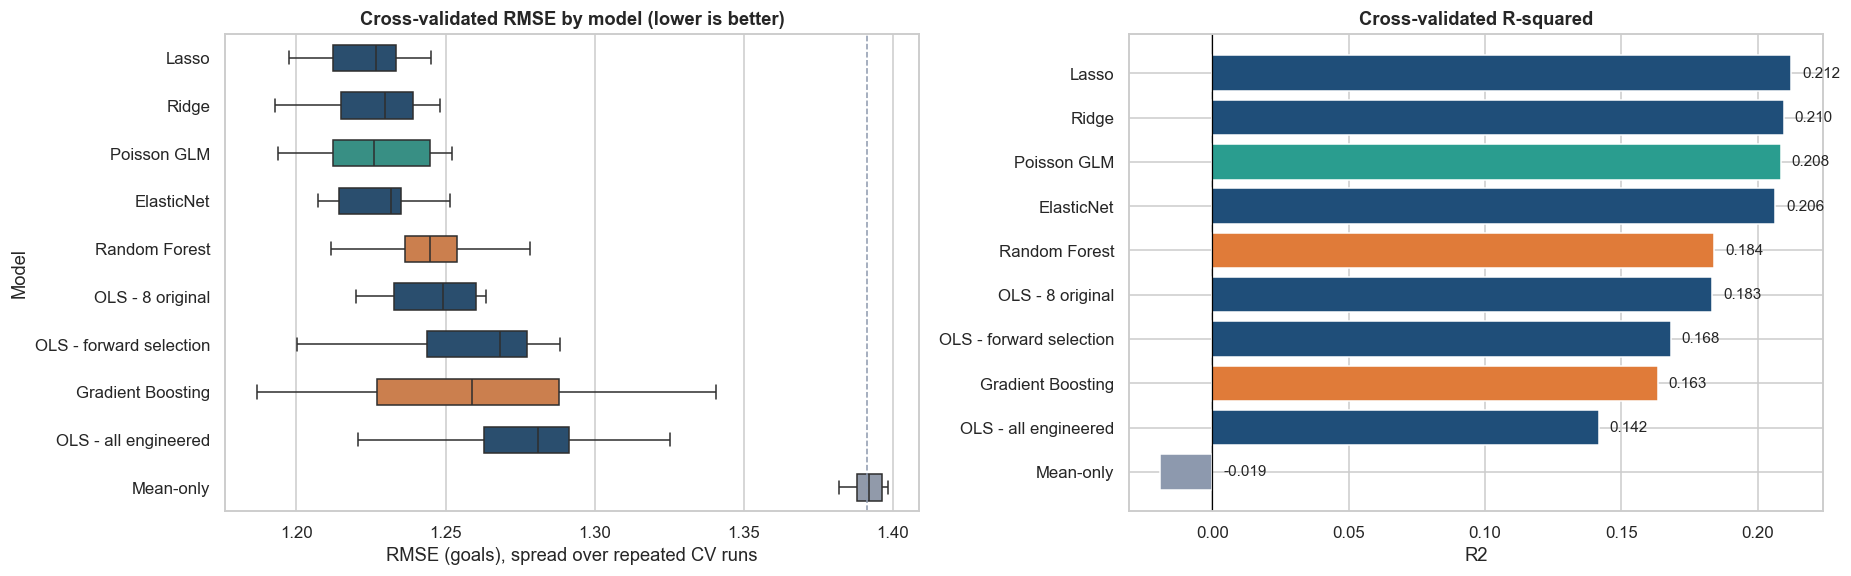

,Mean RMSE diff vs OLS-8,Better in (of 6)
Model,,
Lasso,-0.0223,6
Ridge,-0.0201,5
Poisson GLM,-0.0193,5
ElasticNet,-0.0177,5
Random Forest,-0.0006,3
OLS - 8 original,0.0000,0
OLS - forward selection,0.0113,2
Gradient Boosting,0.0143,3
OLS - all engineered,0.0311,0


In [25]:
order = cmp.index.tolist()
long = pd.concat([r.assign(Model=n) for n, r in cmp_runs.items()])
fam = {n: (C["grey"] if n == "Mean-only" else C["accent"] if n in ("Random Forest", "Gradient Boosting") else C["good"] if n == "Poisson GLM" else C["main"]) for n in order}

fig, ax = plt.subplots(1, 2, figsize=(17, 5.4))
sns.boxplot(data=long, y="Model", x="RMSE", order=order, palette=fam, ax=ax[0], width=.55)
ax[0].axvline(cmp.loc["Mean-only", "RMSE"], color=C["grey"], ls="--", lw=1)
ax[0].set(title="Cross-validated RMSE by model (lower is better)", xlabel="RMSE (goals), spread over repeated CV runs")

r2 = cmp["R2"].reindex(order)
ax[1].barh(r2.index, r2.values, color=[fam[n] for n in r2.index])
for i, v in enumerate(r2.values):
    ax[1].text(max(v, 0) + 0.004, i, f"{v:.3f}", va="center", fontsize=10)
ax[1].axvline(0, color="black", lw=.8); ax[1].invert_yaxis()
ax[1].set(title="Cross-validated R-squared", xlabel="R2")
plt.tight_layout(); plt.show()

# paired comparison against the OLS baseline on identical splits
ref = cmp_runs["OLS - 8 original"]["RMSE"].values
rows = []
for n in order:
    d = cmp_runs[n]["RMSE"].values - ref
    rows.append({"Model": n, "Mean RMSE diff vs OLS-8": d.mean(), "Better in (of %d)" % N_REP: int((d < 0).sum())})
display(pd.DataFrame(rows).set_index("Model").round(4))

**Reading the comparison** (repeated grouped CV on the training matches, nested tuning).

1. **Every feature-based model beats the mean-only reference** (RMSE about 1.39) by a clear margin, so the pre-match information is genuinely informative.
2. **The four regularised models are statistically indistinguishable.** Lasso, Ridge, Poisson GLM and ElasticNet sit within about 0.005 RMSE of each other, which is far smaller than the run-to-run spread (about 0.02). All four beat plain OLS on the original 8 features by roughly 0.02.
3. **Non-linearity does not pay off here.** Random Forest is no better than the 8-feature OLS, and Gradient Boosting is both worse and much less stable. With around 160 rows there is not enough data for flexible models to find structure a linear model misses.
4. **The Poisson model is not better than the linear ones**, so the plain linear regression is a reasonable choice despite the target being a count.
5. **Selection bias is real.** The 4-feature subset looked best when scored on the data that chose it, but once the selection is repeated inside each fold (the honest version) it is clearly worse than the regularised models. This is why the optimism table above matters, and why a naive "pick the best features, then cross-validate" workflow would have overstated performance.

## Step 10 — Choosing the final model

The assessment asks for a **linear regression** model, so the final model is chosen from the linear family. The rule is stated before looking at the test set:

> Take the best cross-validated linear model. If **OLS with forward selection** (a short, readable equation) is within a small tolerance (0.01 goals RMSE) of that best score, prefer it, because it is easier to interpret and defend.

Non-linear and count models are used as *benchmarks*: they tell us whether the linear model is leaving obvious accuracy on the table.

In [26]:
linear_family = ["OLS - 8 original", "OLS - all engineered", "OLS - forward selection", "Ridge", "Lasso", "ElasticNet"]
lin = cmp.loc[linear_family].sort_values("RMSE")
TOL = 0.01
best_linear = lin.index[0]
final_name = "OLS - forward selection" if lin.loc["OLS - forward selection", "RMSE"] <= lin["RMSE"].min() + TOL else best_linear

FINAL_MODEL, FINAL_FEATURES = registry[final_name]
if final_name == "OLS - forward selection":
    # the procedure won, so the final equation is OLS on the subset it finds on the full training set (Step 8.2)
    FINAL_MODEL, FINAL_FEATURES = ols_pipe(), SELECTED
print("Best linear model by CV RMSE:", best_linear, f"({lin['RMSE'].min():.4f})")
print("Final model chosen:", final_name, f"({cmp.loc[final_name, 'RMSE']:.4f})")
print("Final features:", FINAL_FEATURES)

gain = cmp.loc["OLS - 8 original", "RMSE"] - cmp.loc[final_name, "RMSE"]
rel = gain / cmp.loc["OLS - 8 original", "RMSE"] * 100
print(f"Improvement over the 8-feature baseline: {gain:.4f} goals RMSE ({rel:.1f}%)")
display(lin.round(4))

Best linear model by CV RMSE: Lasso (1.2232)
Final model chosen: Lasso (1.2232)
Final features: ['Age', 'Goals_pg3', 'SOT_pg3', 'Strikers_Bench', 'Rank_Diff', 'Corners_pg3', 'KO_Apps', 'Opp_GK_Saves3', 'Opp_Goals_pg3', 'Opp_SOT_pg3', 'Opp_Corners_pg3', 'Own_GK_Saves3', 'Opp_KO_Apps', 'Opp_Age', 'Opp_Strikers', 'Is_Knockout', 'Rank_ssqrt', 'SOT_x_OppGK']
Improvement over the 8-feature baseline: 0.0223 goals RMSE (1.8%)


,Features,RMSE,RMSE sd,MAE,R2
Lasso,18,1.2232,0.0176,0.9289,0.2124
Ridge,18,1.2254,0.0203,0.9439,0.2095
ElasticNet,18,1.2278,0.0171,0.9354,0.2065
OLS - 8 original,8,1.2455,0.0180,0.9611,0.1834
OLS - forward selection,18,1.2569,0.0331,0.9546,0.1681
OLS - all engineered,18,1.2766,0.0352,0.9800,0.1417


**Decision.** The rule selects the **Lasso**: it has the best cross-validated RMSE of the linear family, and the forward-selection OLS is well outside the 0.01 tolerance, so the simpler-equation preference does not apply. Lasso is still linear regression (least squares with an L1 penalty), and it performs feature selection as part of fitting. Because Ridge, ElasticNet and Poisson are statistically tied with it, this choice is made by the pre-set rule rather than because Lasso is decisively better.

## Step 11 — Final evaluation on the locked hold-out matches

The chosen model is refitted on **all training matches** and evaluated, once, on matches it has never seen. Because the test set is small, a **match-level bootstrap** (resampling whole matches, 2,000 times) gives confidence intervals around each metric.

For transparency, all other models are also scored on the test set *after* the decision. These numbers were not used to choose anything.

In [27]:
final_fit = fit_model(FINAL_MODEL, train_fe[FINAL_FEATURES], y_tr, g_tr)
y_te, g_te = test_fe[TARGET], test_fe["Match_ID"]
pred_te = final_fit.predict(test_fe[FINAL_FEATURES])

def cluster_bootstrap(y, p, groups, B=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    ids = groups.unique()
    where = {g: np.where(groups.values == g)[0] for g in ids}
    out = []
    for _ in range(B):
        ii = np.concatenate([where[g] for g in rng.choice(ids, size=len(ids), replace=True)])
        out.append((r2_score(y.iloc[ii], p[ii]), rmse(y.iloc[ii], p[ii]), mean_absolute_error(y.iloc[ii], p[ii])))
    return np.percentile(np.array(out), [2.5, 97.5], axis=0)

ci = cluster_bootstrap(y_te, pred_te, g_te)
test_metrics = pd.DataFrame({
    "Estimate": [r2_score(y_te, pred_te), rmse(y_te, pred_te), mean_absolute_error(y_te, pred_te)],
    "95% CI low": ci[0], "95% CI high": ci[1]}, index=["R2", "RMSE", "MAE"])
display(test_metrics.round(3))

base_pred = fit_model(registry["Mean-only"][0], train_fe[POOL], y_tr, g_tr).predict(test_fe[POOL])
print(f"Reference: mean-only model on the same test rows has RMSE {rmse(y_te, base_pred):.3f}, MAE {mean_absolute_error(y_te, base_pred):.3f}")

rows = []
for n, (mdl, feats) in registry.items():
    m = fit_model(mdl, train_fe[feats], y_tr, g_tr)
    p = m.predict(test_fe[feats])
    rows.append({"Model": n, "CV RMSE (train)": cmp.loc[n, "RMSE"], "Test RMSE": rmse(y_te, p), "Test MAE": mean_absolute_error(y_te, p), "Test R2": r2_score(y_te, p)})
display(pd.DataFrame(rows).set_index("Model").sort_values("CV RMSE (train)").round(3))

,Estimate,95% CI low,95% CI high
R2,0.324,0.068,0.476
RMSE,1.180,0.878,1.508
MAE,0.905,0.685,1.156


Reference: mean-only model on the same test rows has RMSE 1.435, MAE 1.139


,CV RMSE (train),Test RMSE,Test MAE,Test R2
Model,,,,
Lasso,1.223,1.180,0.905,0.324
Ridge,1.225,1.217,0.935,0.281
Poisson GLM,1.226,1.211,0.919,0.288
ElasticNet,1.228,1.202,0.920,0.298
Random Forest,1.245,1.181,0.907,0.323
OLS - 8 original,1.246,1.280,0.985,0.204
OLS - forward selection,1.257,1.167,0.891,0.339
Gradient Boosting,1.260,1.239,0.948,0.255
OLS - all engineered,1.277,1.187,0.906,0.316


C:\Users\DELL\AppData\Local\Temp\ipykernel_18020\1113583562.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=stage_resid, x="Group", y="Abs error", palette=[C["main"], C["accent"]], ax=ax[2])


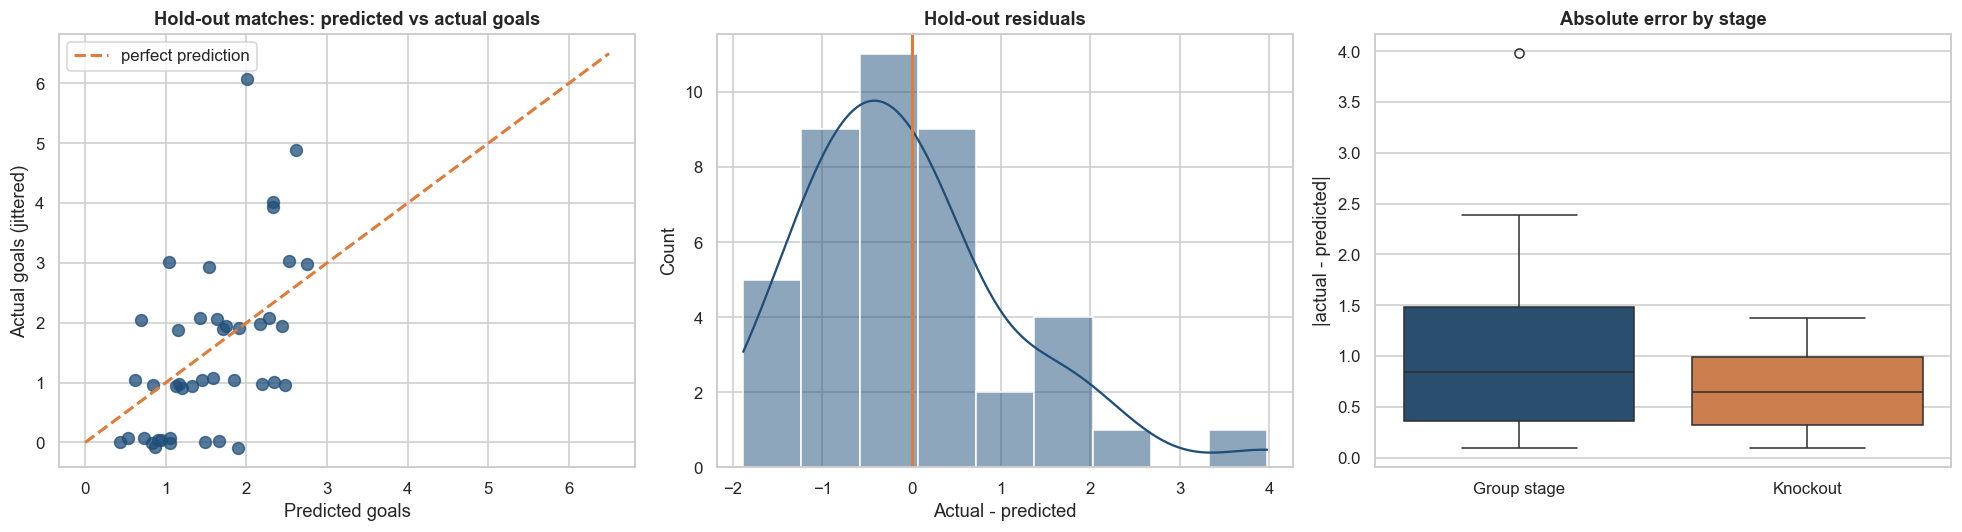

In [28]:
resid_te = y_te.values - pred_te
rng = np.random.default_rng(SEED)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].scatter(pred_te + rng.uniform(-.03, .03, len(pred_te)), y_te + rng.uniform(-.12, .12, len(y_te)), color=C["main"], alpha=.75, s=60)
lim = [0, max(pred_te.max(), y_te.max()) + .5]
ax[0].plot(lim, lim, "--", color=C["accent"], lw=2, label="perfect prediction"); ax[0].legend()
ax[0].set(title="Hold-out matches: predicted vs actual goals", xlabel="Predicted goals", ylabel="Actual goals (jittered)")

sns.histplot(resid_te, kde=True, color=C["main"], ax=ax[1])
ax[1].axvline(0, color=C["accent"], lw=2); ax[1].set(title="Hold-out residuals", xlabel="Actual - predicted")

stage_resid = pd.DataFrame({"Group": np.where(test_fe["Is_Knockout"] == 1, "Knockout", "Group stage"), "Abs error": np.abs(resid_te)})
sns.boxplot(data=stage_resid, x="Group", y="Abs error", palette=[C["main"], C["accent"]], ax=ax[2])
ax[2].set(title="Absolute error by stage", xlabel="", ylabel="|actual - predicted|")
plt.tight_layout(); plt.show()

**Reading the hold-out results.**

- On 21 unseen matches the final model's RMSE is about 1.18 goals (95% bootstrap range roughly 0.88 to 1.51), against 1.44 for the mean-only reference on the same rows. R² is about 0.32 with a wide range (roughly 0.07 to 0.48) because the test set is small. The point estimate agrees with the cross-validated result (RMSE about 1.22), which is reassuring: there is no sign of the model having been over-tuned to the training data.
- The all-models table shows a slightly different order than the CV table. That is expected noise with only 42 test rows, and it is exactly why decisions were taken from repeated CV, *not* from the test set.
- Errors are right-skewed: the model rarely over-predicts by much, but it cannot anticipate the occasional 4–7 goal match. That is a property of football scoring, not a modelling bug.

### 11.1 Stability check on all 104 matches
A 21-match test set is small, so the final model is also scored with repeated grouped CV on the **full dataset**. This gives out-of-fold predictions for every match, which power the calibration, team-level and match-outcome analysis below.

Repeated grouped CV on all 208 rows:


,RMSE,RMSE sd,MAE,R2
value,1.208,0.013,0.92,0.244


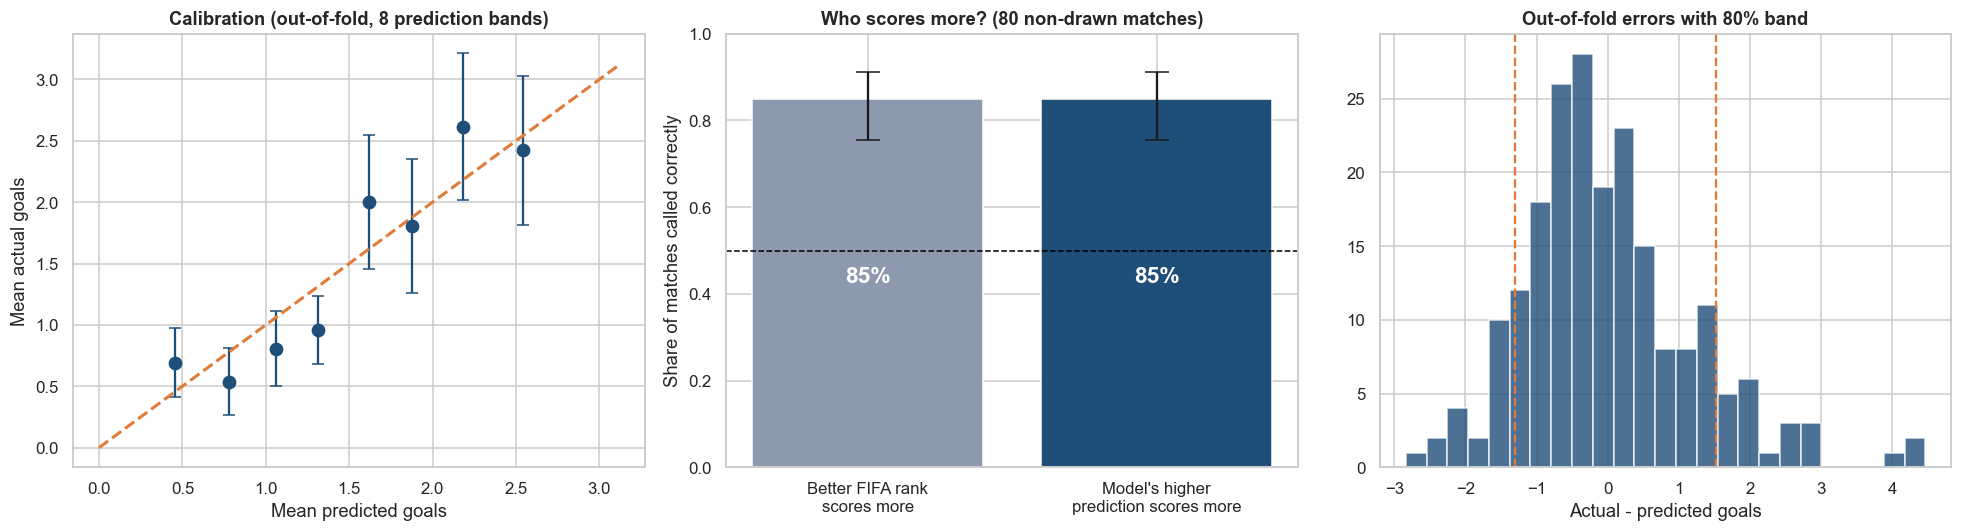

80% prediction band: prediction -1.31 to +1.53 goals | coverage on hold-out matches: 76%


In [29]:
res_full, oof_full = evaluate(FINAL_MODEL, fe_all[FINAL_FEATURES], fe_all[TARGET], fe_all["Match_ID"], n_repeats=10, seed=900)
print("Repeated grouped CV on all 208 rows:")
display(summarise(res_full).round(3).to_frame("value").T)

oof = fe_all[["Match_ID", "Team_Name", "Goals", "Rank_Diff", "Stage"]].copy()
oof["Pred"] = oof_full
oof["Resid"] = oof["Goals"] - oof["Pred"]

# calibration: do predicted goals match actual goals on average?
oof["Bin"] = pd.qcut(oof["Pred"], 8, duplicates="drop")
cal = oof.groupby("Bin", observed=True).agg(pred=("Pred", "mean"), actual=("Goals", "mean"), n=("Goals", "size"))
se = oof.groupby("Bin", observed=True)["Goals"].sem()

# prediction intervals from out-of-fold residuals
lo_q, hi_q = np.percentile(oof["Resid"], [10, 90])
cover = ((y_te.values >= pred_te + lo_q) & (y_te.values <= pred_te + hi_q)).mean()

# match outcome: does the team predicted to score more actually score more?
pairs = oof.merge(oof, on="Match_ID")
pairs = pairs[pairs["Team_Name_x"] < pairs["Team_Name_y"]]
dec = pairs[pairs["Goals_x"] != pairs["Goals_y"]].copy()
dec["model_ok"] = np.sign(dec["Pred_x"] - dec["Pred_y"]) == np.sign(dec["Goals_x"] - dec["Goals_y"])
dec["rank_ok"] = np.sign(-dec["Rank_Diff_x"]) == np.sign(dec["Goals_x"] - dec["Goals_y"])
m_acc, r_acc = dec["model_ok"].mean(), dec["rank_ok"].mean()
m_ci = proportion_confint(dec["model_ok"].sum(), len(dec), method="wilson")
r_ci = proportion_confint(dec["rank_ok"].sum(), len(dec), method="wilson")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].errorbar(cal["pred"], cal["actual"], yerr=1.96 * se, fmt="o", color=C["main"], capsize=4, ms=8)
lim = [0, max(cal["pred"].max(), cal["actual"].max()) + .5]
ax[0].plot(lim, lim, "--", color=C["accent"], lw=2)
ax[0].set(title="Calibration (out-of-fold, 8 prediction bands)", xlabel="Mean predicted goals", ylabel="Mean actual goals")

ax[1].bar(["Better FIFA rank\nscores more", "Model's higher\nprediction scores more"], [r_acc, m_acc], color=[C["grey"], C["main"]],
          yerr=[[r_acc - r_ci[0], m_acc - m_ci[0]], [r_ci[1] - r_acc, m_ci[1] - m_acc]], capsize=8)
ax[1].axhline(0.5, color="black", ls="--", lw=1)
for i, v in enumerate([r_acc, m_acc]):
    ax[1].text(i, v / 2, f"{v:.0%}", ha="center", color="white", fontsize=15, fontweight="bold")
ax[1].set(title=f"Who scores more? ({len(dec)} non-drawn matches)", ylim=(0, 1), ylabel="Share of matches called correctly")

ax[2].hist(oof["Resid"], bins=25, color=C["main"], alpha=.8)
ax[2].axvline(lo_q, color=C["accent"], ls="--"); ax[2].axvline(hi_q, color=C["accent"], ls="--")
ax[2].set(title="Out-of-fold errors with 80% band", xlabel="Actual - predicted goals")
plt.tight_layout(); plt.show()
print(f"80% prediction band: prediction {lo_q:+.2f} to {hi_q:+.2f} goals | coverage on hold-out matches: {cover:.0%}")

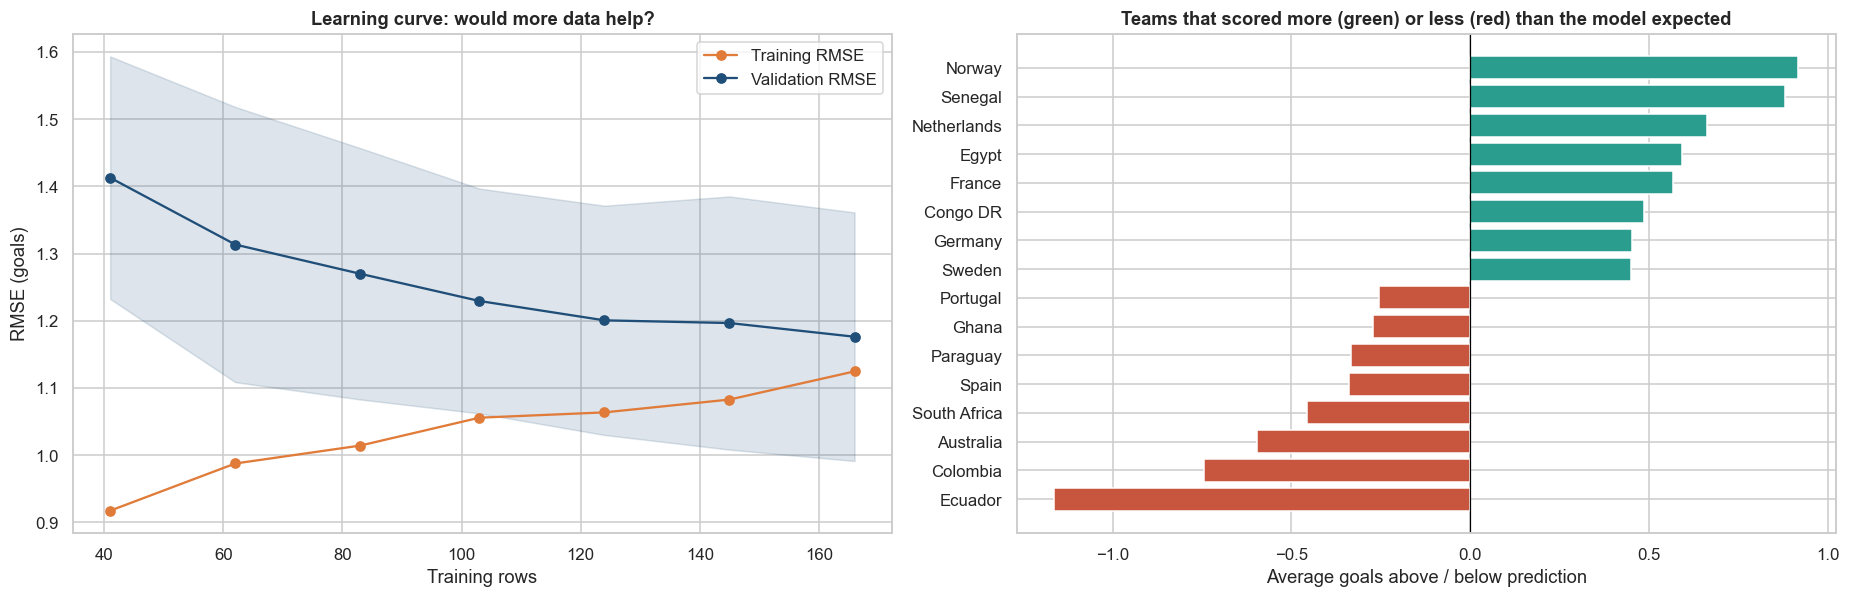

In [30]:
lc_est = clone(final_fit.best_estimator_) if isinstance(final_fit, GridSearchCV) else clone(FINAL_MODEL)
fig, ax = plt.subplots(1, 2, figsize=(17, 5.6))

sizes, tr_sc, va_sc = learning_curve(
    lc_est, fe_all[FINAL_FEATURES], fe_all[TARGET], groups=fe_all["Match_ID"],
    cv=group_kfold(5, SEED), train_sizes=np.linspace(0.25, 1.0, 7), scoring="neg_root_mean_squared_error", shuffle=True, random_state=SEED)
ax[0].plot(sizes, -tr_sc.mean(1), "o-", color=C["accent"], label="Training RMSE")
ax[0].plot(sizes, -va_sc.mean(1), "o-", color=C["main"], label="Validation RMSE")
ax[0].fill_between(sizes, -va_sc.mean(1) - va_sc.std(1), -va_sc.mean(1) + va_sc.std(1), color=C["main"], alpha=.15)
ax[0].set(title="Learning curve: would more data help?", xlabel="Training rows", ylabel="RMSE (goals)"); ax[0].legend()

team_res = oof.groupby("Team_Name")["Resid"].agg(["mean", "count"])
team_res = team_res[team_res["count"] >= 4].sort_values("mean")
show = pd.concat([team_res.head(8), team_res.tail(8)])
ax[1].barh(show.index, show["mean"], color=[C["bad"] if v < 0 else C["good"] for v in show["mean"]])
ax[1].axvline(0, color="black", lw=.8)
ax[1].set(title="Teams that scored more (green) or less (red) than the model expected", xlabel="Average goals above / below prediction")
plt.tight_layout(); plt.show()

**Reading the stability checks.**

- **Calibration:** across eight prediction bands the average actual goals track the diagonal, with the error bars overlapping it everywhere, so predictions are not systematically too high or too low. The 80% error band covers roughly three quarters to four fifths of hold-out matches, close to its nominal level.
- **Picking the higher scorer:** among the 80 matches that were not draws, the model and a simple "better FIFA ranking scores more" rule are equally accurate (about 85%). The ranking gap already carries the directional information; the model's added value is more accurate *goal counts*, not a better winner call.
- **Learning curve:** validation error is still drifting down at the largest training size while training error rises, so the model is limited more by the small number of matches than by its form. More matches would help modestly.
- **Team-level view:** teams such as Norway, Senegal and the Netherlands scored above what their pre-match profile predicted, while Ecuador, Colombia and Australia scored below it. With only 4–8 matches per team, treat this as descriptive context, not proof of team quality.

## Step 12 — Understanding the final model

The final model is refitted on **all 104 matches** (accuracy was already judged on held-out data, so this step is about *understanding* effects, and more data gives more precise estimates).

Regularised models do not have classical p-values, and shrinkage plus feature selection makes textbook confidence intervals invalid. The honest alternative is a **match-level bootstrap**: refit the model on 400 resamples of matches and look at how the coefficients behave. This captures the uncertainty from *both* estimation and feature selection.

Coefficients below are on the standardised scale, so each one reads as *"extra expected goals for a one-standard-deviation increase in that feature"*, which makes variables with different units comparable.

In [31]:
final_all = fit_model(FINAL_MODEL, fe_all[FINAL_FEATURES], fe_all[TARGET], fe_all["Match_ID"])
core = final_all.best_estimator_ if isinstance(final_all, GridSearchCV) else final_all
scaler, linmod = core[0], core[-1]
if isinstance(final_all, GridSearchCV):
    print("Tuned hyperparameters:", final_all.best_params_)

sd = pd.Series(scaler.scale_, index=FINAL_FEATURES)
mu = pd.Series(scaler.mean_, index=FINAL_FEATURES)
std_coef = pd.Series(linmod.coef_, index=FINAL_FEATURES)
per_unit = std_coef / sd
intercept = linmod.intercept_ - (per_unit * mu).sum()
print(f"Non-zero coefficients: {(std_coef.abs() > 1e-8).sum()} of {len(FINAL_FEATURES)}")

def bootstrap_coefs(estimator, data, features, B=400, seed=SEED):
    rng = np.random.default_rng(seed)
    ids = data["Match_ID"].unique()
    where = {g: np.where(data["Match_ID"].values == g)[0] for g in ids}
    draws = []
    for _ in range(B):
        ii = np.concatenate([where[g] for g in rng.choice(ids, size=len(ids), replace=True)])
        m = clone(estimator).fit(data.iloc[ii][features], data.iloc[ii][TARGET])
        draws.append(m[-1].coef_)
    return pd.DataFrame(draws, columns=features)

boot = bootstrap_coefs(core, fe_all, FINAL_FEATURES)
stab = pd.DataFrame({
    "Effect of +1 SD (goals)": std_coef,
    "Boot 2.5%": boot.quantile(.025), "Boot 97.5%": boot.quantile(.975),
    "Kept by model (% of resamples)": (boot.abs() > 1e-8).mean() * 100,
    "Same sign as full fit (%)": [(np.sign(boot[c]) == np.sign(std_coef[c])).mean() * 100 if abs(std_coef[c]) > 1e-8 else np.nan for c in FINAL_FEATURES],
    "Per original unit": per_unit,
}).sort_values("Effect of +1 SD (goals)", key=abs, ascending=False)
display(stab.round(3))

Tuned hyperparameters: {'lasso__alpha': np.float64(0.05623413251903491)}
Non-zero coefficients: 8 of 18


,Effect of +1 SD (goals),Boot 2.5%,Boot 97.5%,Kept by model (% of resamples),Same sign as full fit (%),Per original unit
Rank_ssqrt,-0.424,-0.587,0.000,97.25,97.25,-0.081
Opp_SOT_pg3,-0.246,-0.403,0.000,93.00,93.00,-0.135
KO_Apps,0.244,0.021,0.485,99.00,99.00,0.076
Age,-0.152,-0.304,0.000,95.00,95.00,-0.139
SOT_x_OppGK,-0.072,-0.227,0.000,86.50,86.25,-0.032
Goals_pg3,-0.051,-0.214,0.000,68.25,67.75,-0.060
Opp_Goals_pg3,-0.040,-0.304,0.000,60.25,59.75,-0.047
Strikers_Bench,0.030,0.000,0.160,62.50,61.25,0.030
Corners_pg3,0.000,-0.083,0.181,46.00,NaN,0.000
Rank_Diff,-0.000,-0.360,0.000,35.00,NaN,-0.000


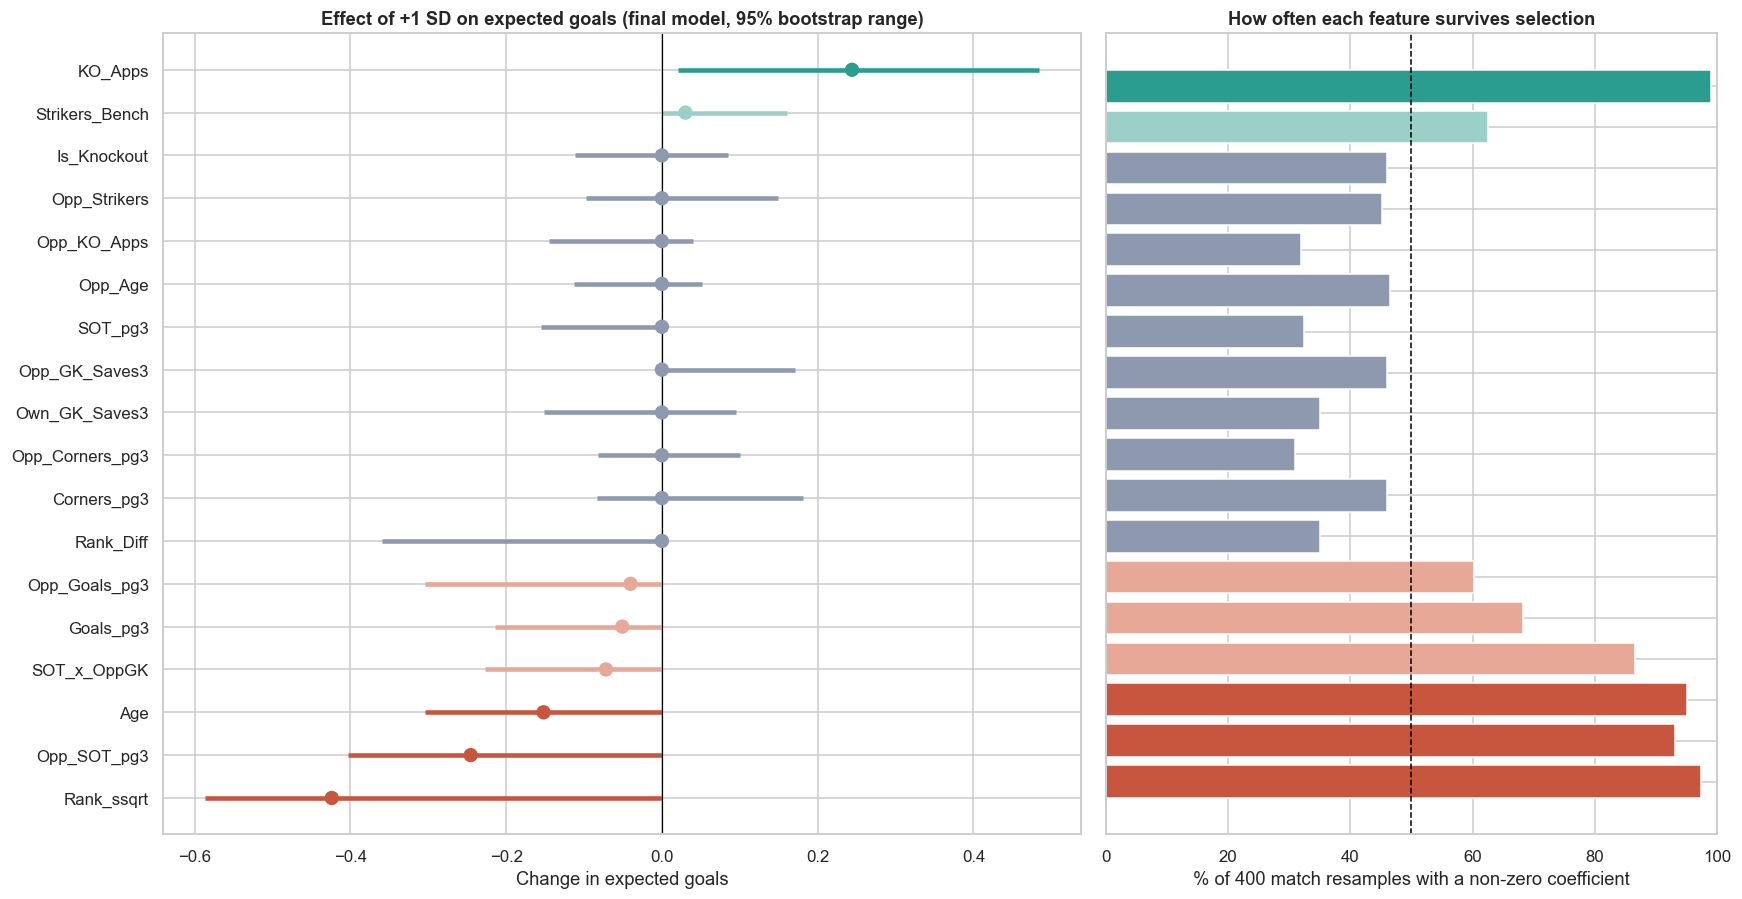

Strong green/red = kept in at least 90% of resamples (positive/negative effect); light = kept in 60-90%; grey = kept in under 60%, i.e. not reliable.


In [32]:
plot = stab.sort_values("Effect of +1 SD (goals)")

def tier_colour(effect, kept):
    # stable (kept in >= 90% of resamples) = strong colour, borderline (60-90%) = light colour, otherwise grey
    if kept >= 90:
        return C["good"] if effect > 0 else C["bad"]
    if kept >= 60:
        return "#9bd0c8" if effect > 0 else "#e8a898"
    return C["grey"]

cols = [tier_colour(e, k) for e, k in zip(plot["Effect of +1 SD (goals)"], plot["Kept by model (% of resamples)"])]

fig, ax = plt.subplots(1, 2, figsize=(16, max(5, 0.38 * len(plot) + 1.5)), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].hlines(plot.index, plot["Boot 2.5%"], plot["Boot 97.5%"], color=cols, lw=3)
ax[0].scatter(plot["Effect of +1 SD (goals)"], plot.index, color=cols, s=70, zorder=3)
ax[0].axvline(0, color="black", lw=.8)
ax[0].set(title="Effect of +1 SD on expected goals (final model, 95% bootstrap range)", xlabel="Change in expected goals")

ax[1].barh(plot.index, plot["Kept by model (% of resamples)"], color=cols)
ax[1].axvline(50, color="black", ls="--", lw=1)
ax[1].set(title="How often each feature survives selection", xlabel="% of 400 match resamples with a non-zero coefficient", xlim=(0, 100))
ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()
print("Strong green/red = kept in at least 90% of resamples (positive/negative effect); light = kept in 60-90%; grey = kept in under 60%, i.e. not reliable.")

**What the final model uses.** The tuned Lasso (penalty about 0.056) keeps 8 of the 18 candidate features. Four of them are stable, meaning they survive in at least 93% of the match resamples with a consistent sign:

- **Ranking gap (signed square root): about -0.42 goals per +1 SD.** A better-ranked team scores more.
- **Knockout pedigree (`KO_Apps`): about +0.24 goals per +1 SD.** Kept in 99% of resamples, and the only coefficient whose bootstrap range stays strictly above zero.
- **Opponent's recent shots on target: about -0.25 goals per +1 SD.** When the opponent has recently been shot-heavy, the team scores less, consistent with a more dominant opponent.
- **Squad age: about -0.15 goals per +1 SD** (roughly 0.14 fewer goals per extra year of average age).

The other four selected features (the shot-volume × goalkeeper-workload interaction, team goals per game, opponent goals per game and strikers on the bench) appear in only 60–87% of resamples and have tiny effects, so treat them as tentative. The ten dropped features, including the original `Rank_Diff` (which its square-root version replaces), `SOT_pg3`, `Corners_pg3` and the knockout flag, carry no reliable extra signal.

### 12.1 Does the final model satisfy the regression assumptions?
The classical diagnostics in Step 7 relied on the OLS fit. For the final model they are repeated using its **out-of-fold residuals** (every residual comes from a model that never saw that match), which is the more honest version.

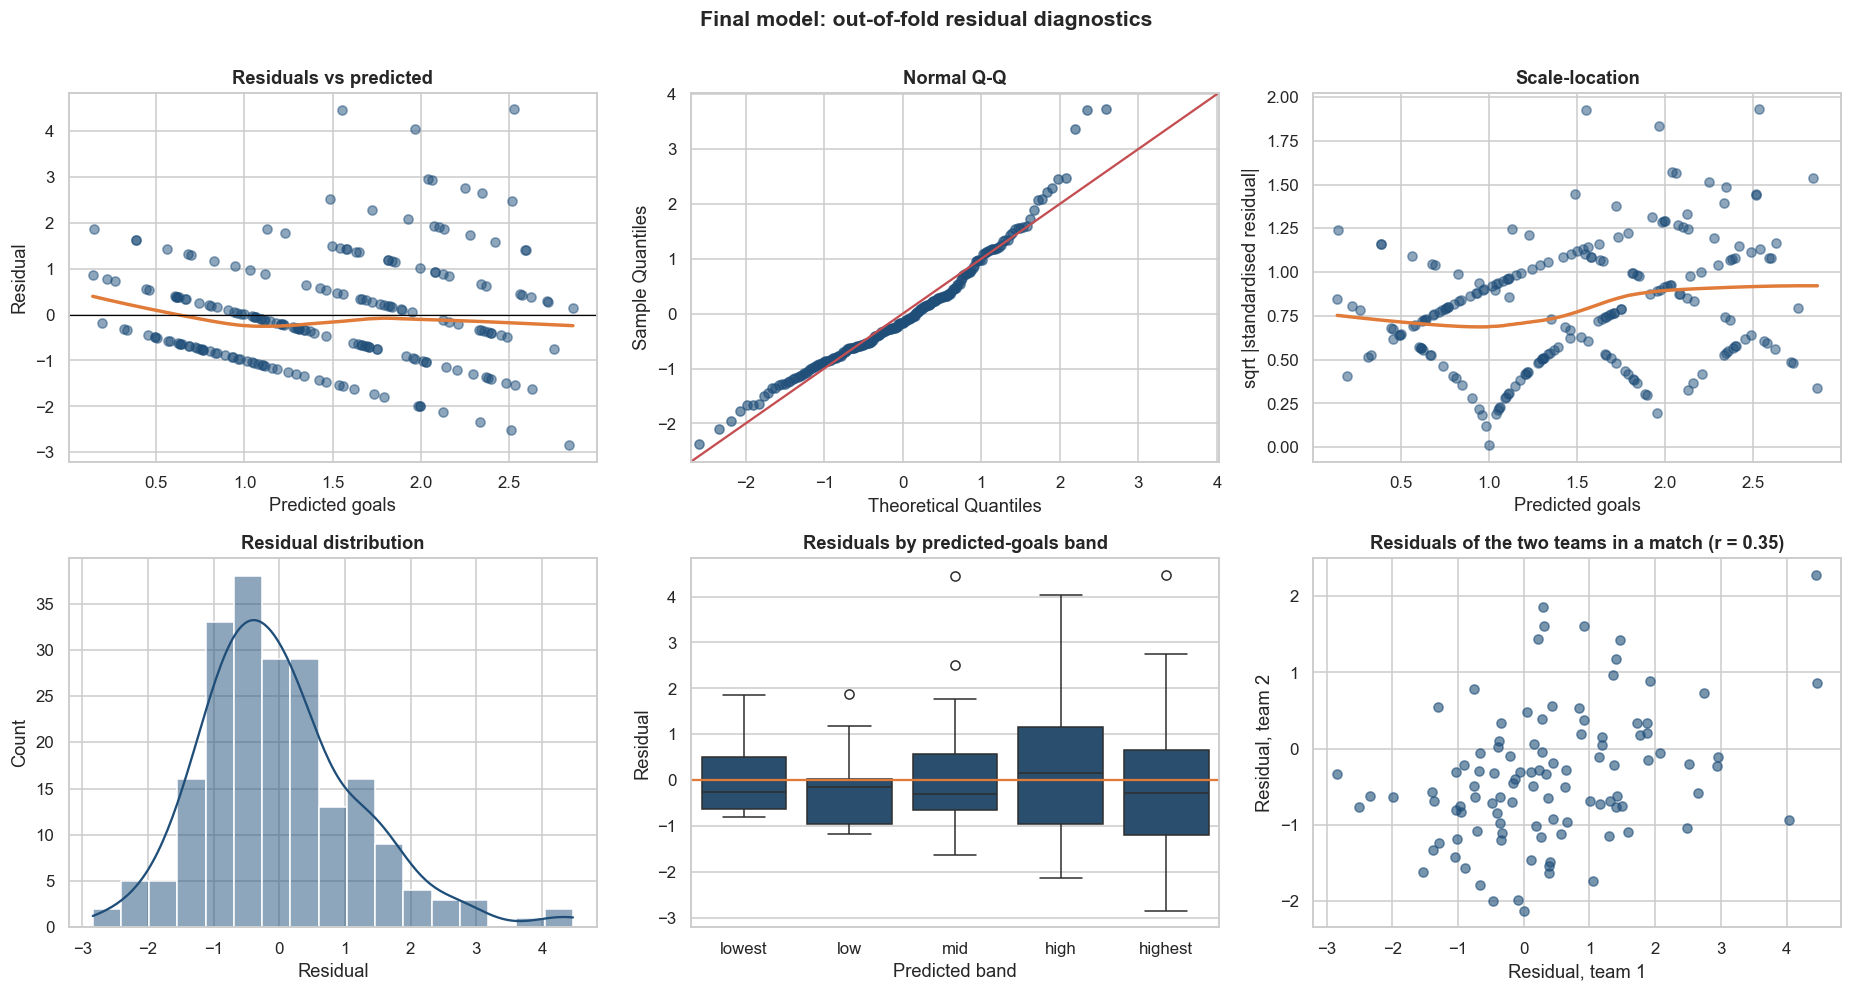

,value
Mean residual (bias),0.0012
Shapiro-Wilk p (normal residuals),0.0000
Residual skew,0.8676
"Spearman(|residual|, predicted)",0.2516
p-value (constant variance),0.0002
Within-match residual correlation,0.3513
p-value,0.0003


In [33]:
def residual_diagnostics(pred, actual, groups, title=""):
    pred, actual = np.asarray(pred), np.asarray(actual)
    resid = actual - pred
    z = (resid - resid.mean()) / resid.std()
    fig, ax = plt.subplots(2, 3, figsize=(17, 9))

    ax[0, 0].scatter(pred, resid, alpha=.5, color=C["main"])
    sns.regplot(x=pred, y=resid, lowess=True, scatter=False, line_kws={"color": C["accent"]}, ax=ax[0, 0])
    ax[0, 0].axhline(0, color="black", lw=.8); ax[0, 0].set(title="Residuals vs predicted", xlabel="Predicted goals", ylabel="Residual")

    sm.qqplot(z, line="45", ax=ax[0, 1], markerfacecolor=C["main"], markeredgecolor=C["main"], alpha=.6)
    ax[0, 1].set_title("Normal Q-Q")

    ax[0, 2].scatter(pred, np.sqrt(np.abs(z)), alpha=.5, color=C["main"])
    sns.regplot(x=pred, y=np.sqrt(np.abs(z)), lowess=True, scatter=False, line_kws={"color": C["accent"]}, ax=ax[0, 2])
    ax[0, 2].set(title="Scale-location", xlabel="Predicted goals", ylabel="sqrt |standardised residual|")

    sns.histplot(resid, kde=True, color=C["main"], ax=ax[1, 0]); ax[1, 0].set(title="Residual distribution", xlabel="Residual")

    band = pd.qcut(pred, 5, labels=["lowest", "low", "mid", "high", "highest"])
    sns.boxplot(x=band, y=resid, color=C["main"], ax=ax[1, 1])
    ax[1, 1].axhline(0, color=C["accent"], lw=1.5); ax[1, 1].set(title="Residuals by predicted-goals band", xlabel="Predicted band", ylabel="Residual")

    tmp = pd.DataFrame({"g": np.asarray(groups), "r": resid})
    pair = tmp.groupby("g")["r"].apply(list)
    a = np.array([v[0] for v in pair]); b = np.array([v[1] for v in pair])
    rc, rp = stats.pearsonr(a, b)
    ax[1, 2].scatter(a, b, alpha=.6, color=C["main"])
    ax[1, 2].set(title=f"Residuals of the two teams in a match (r = {rc:.2f})", xlabel="Residual, team 1", ylabel="Residual, team 2")
    plt.suptitle(title, y=1.0, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

    het = stats.spearmanr(pred, np.abs(resid))
    return pd.Series({
        "Mean residual (bias)": resid.mean(),
        "Shapiro-Wilk p (normal residuals)": stats.shapiro(resid).pvalue,
        "Residual skew": stats.skew(resid),
        "Spearman(|residual|, predicted)": het.statistic,
        "  p-value (constant variance)": het.pvalue,
        "Within-match residual correlation": rc,
        "  p-value": rp,
    })

diag_final = residual_diagnostics(oof["Pred"], oof["Goals"], oof["Match_ID"], "Final model: out-of-fold residual diagnostics")
display(diag_final.round(4).to_frame("value"))

**Reading the final-model diagnostics.** The out-of-fold residuals are essentially unbiased (mean about 0) but the same assumption problems seen in the baseline remain: they are right-skewed (skew about 0.87), their spread grows with the predicted goals (Spearman 0.25, p ≈ 0.0002), and the two teams' residuals in the same match are positively correlated (r about 0.35, p ≈ 0.0003). These are properties of the data (a count outcome and a shared match "tempo"), not something these features fix. Practical consequences: prediction bands should be wider for high-scoring favourites, a match-level model of total goals is the natural next step, and inference should rely on the bootstrap rather than textbook p-values.

### 12.2 Feature-level analysis: which information is the model really using?
Two ablation views, both scored with the repeated grouped CV on the training matches (the tuned penalty is held fixed):

- **Drop-one:** remove a single feature and see how much the error changes.
- **Group ablation:** remove a whole *family* of related features. This is more informative when features overlap (for example `Rank_Diff` and `Rank_ssqrt` carry the same signal, so removing only one changes little).

Positive numbers mean the error **rose** when the information was removed, so it was useful.

,Features removed,RMSE increase when removed,Worse in (of 10)
Group,,,
Team's own recent form,3,-0.0060,0
Goalkeeper workload & shot interaction,3,-0.0057,3
Knockout flag,1,-0.0028,2
Squad profile,4,-0.0019,5
Opponent's recent form,3,0.0153,10
Ranking & tournament pedigree,4,0.1278,10


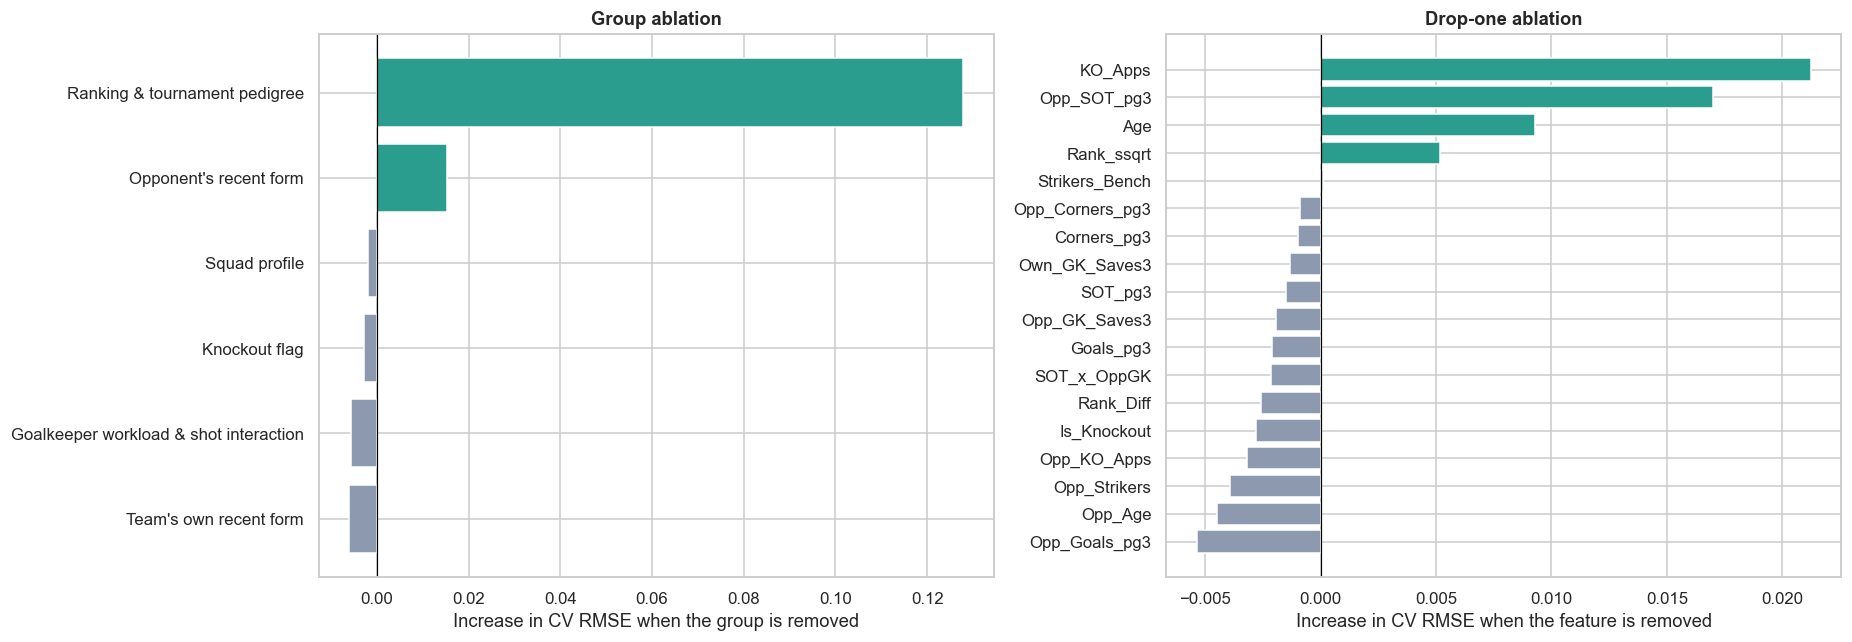

In [34]:
fixed = clone(core)
ref_res, _ = evaluate(fixed, train_fe[FINAL_FEATURES], y_tr, g_tr, n_repeats=10)
ref_rmse = ref_res["RMSE"].mean()

rows = []
for f in FINAL_FEATURES:
    res, _ = evaluate(fixed, train_fe[[c for c in FINAL_FEATURES if c != f]], y_tr, g_tr, n_repeats=10)
    rows.append({"Feature": f, "RMSE increase when removed": res["RMSE"].mean() - ref_rmse})
drop_one = pd.DataFrame(rows).set_index("Feature").sort_values("RMSE increase when removed")

GROUPS = {
    "Ranking & tournament pedigree": ["Rank_Diff", "Rank_ssqrt", "KO_Apps", "Opp_KO_Apps"],
    "Team's own recent form": ["Goals_pg3", "SOT_pg3", "Corners_pg3"],
    "Opponent's recent form": ["Opp_Goals_pg3", "Opp_SOT_pg3", "Opp_Corners_pg3"],
    "Goalkeeper workload & shot interaction": ["Opp_GK_Saves3", "Own_GK_Saves3", "SOT_x_OppGK"],
    "Squad profile": ["Age", "Opp_Age", "Strikers_Bench", "Opp_Strikers"],
    "Knockout flag": ["Is_Knockout"],
}
rows = []
for name, cols_ in GROUPS.items():
    cols_ = [c for c in cols_ if c in FINAL_FEATURES]
    res, _ = evaluate(fixed, train_fe[[c for c in FINAL_FEATURES if c not in cols_]], y_tr, g_tr, n_repeats=10)
    rows.append({"Group": name, "Features removed": len(cols_), "RMSE increase when removed": res["RMSE"].mean() - ref_rmse,
                 "Worse in (of 10)": int((res["RMSE"].values > ref_res["RMSE"].values).sum())})
group_abl = pd.DataFrame(rows).set_index("Group").sort_values("RMSE increase when removed")
display(group_abl.round(4))

fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ax[0].barh(group_abl.index, group_abl["RMSE increase when removed"], color=[C["good"] if v > 0 else C["grey"] for v in group_abl["RMSE increase when removed"]])
ax[0].axvline(0, color="black", lw=.8); ax[0].set(title="Group ablation", xlabel="Increase in CV RMSE when the group is removed")
ax[1].barh(drop_one.index, drop_one["RMSE increase when removed"], color=[C["good"] if v > 0 else C["grey"] for v in drop_one["RMSE increase when removed"]])
ax[1].axvline(0, color="black", lw=.8); ax[1].set(title="Drop-one ablation", xlabel="Increase in CV RMSE when the feature is removed")
plt.tight_layout(); plt.show()

**Reading the ablation.** Two families of information matter. Removing **ranking and tournament pedigree** raises the CV error by about 0.13 goals (worse in all 10 repeats), and removing the **opponent's recent form** raises it by about 0.015 (also worse in all 10). Removing the team's own recent form, goalkeeper workload, squad profile or the knockout flag leaves the error unchanged or marginally lower (by 0.002 to 0.006), meaning these families add no detectable out-of-sample accuracy once ranking, pedigree and opponent form are known.

This is a useful, slightly counter-intuitive finding: the team's *own* recent goals, shots and corners, the variables that took the most effort to collect, add nothing beyond ranking and pedigree in this dataset, whereas the opponent's recent shot volume does.

### 12.3 The final equation, the biggest surprises, and sensitivity
The equation below uses original units. The table lists the rows where the model was most wrong (out-of-fold). The last table refits the model without those rows to check that conclusions do not hinge on a handful of extreme matches.

In [35]:
active = per_unit[std_coef.abs() > 1e-8].sort_values(key=abs, ascending=False)
terms = " ".join(f"{c:+.3f} x {n}" for n, c in active.items())
print(f"Expected goals = {intercept:.3f} {terms}")
print(f"({len(active)} of {len(FINAL_FEATURES)} features have a non-zero coefficient)\n")

surprise = oof.assign(Abs=oof["Resid"].abs()).sort_values("Abs", ascending=False).head(6)
display(surprise.merge(fe_all[["Match_ID", "Team_Name", "Opposition_Team_Name"]], on=["Match_ID", "Team_Name"])[["Match_ID", "Team_Name", "Opposition_Team_Name", "Stage", "Goals", "Pred", "Resid"]].round(2))

keep = np.ones(len(fe_all), dtype=bool)
keep[surprise.index.values] = False
m2 = clone(core).fit(fe_all.loc[keep, FINAL_FEATURES], fe_all.loc[keep, TARGET])
sens = pd.DataFrame({"All rows": std_coef, "Without the 6 biggest misses": pd.Series(m2[-1].coef_, index=FINAL_FEATURES)})
sens = sens[(sens.abs() > 1e-8).any(axis=1)]
sens["Same sign"] = np.sign(sens["All rows"]) == np.sign(sens["Without the 6 biggest misses"])
display(sens.sort_values("All rows", key=abs, ascending=False).round(3))

Expected goals = 5.924 -0.139 x Age -0.135 x Opp_SOT_pg3 -0.081 x Rank_ssqrt +0.076 x KO_Apps -0.060 x Goals_pg3 -0.047 x Opp_Goals_pg3 -0.032 x SOT_x_OppGK +0.030 x Strikers_Bench
(8 of 18 features have a non-zero coefficient)



,Match_ID,Team_Name,Opposition_Team_Name,Stage,Goals,Pred,Resid
0,14-jun-ge-cu,Germany,Curacao,First Stage,7,2.53,4.47
1,19-jul-fr-en,England,France,Bronze final,6,1.55,4.45
2,18-jun-ca-qa,Canada,Qatar,First Stage,6,1.97,4.03
3,20-jun-ne-sd,Netherlands,Sweden,First Stage,5,2.04,2.96
4,15-jun-sd-tn,Sweden,Tunisia,First Stage,5,2.06,2.94
5,23-jun-en-gh,England,Ghana,First Stage,0,2.84,-2.84


,All rows,Without the 6 biggest misses,Same sign
Rank_ssqrt,-0.424,-0.409,True
Opp_SOT_pg3,-0.246,-0.225,True
KO_Apps,0.244,0.188,True
Age,-0.152,-0.122,True
SOT_x_OppGK,-0.072,-0.025,True
Goals_pg3,-0.051,-0.016,True
Opp_Goals_pg3,-0.040,-0.004,True
Strikers_Bench,0.030,0.000,False
Opp_Strikers,0.000,-0.025,False


**Reading the equation and the biggest misses.** The largest errors are scoring extremes that no pre-match feature could anticipate (Germany 7–0 Curaçao, England's 6 goals in the Bronze final, Canada 6 against Qatar) plus one blank (England 0 against Ghana). When the six biggest misses are removed, the four main effects keep the same sign and similar size (ranking gap -0.42 to -0.41, opponent shots -0.25 to -0.23, pedigree 0.24 to 0.19, age -0.15 to -0.12), so the conclusions do not rest on a few extreme matches. The weaker terms (interaction, team goals, opponent goals) shrink towards zero, confirming they are fragile. The two striker terms only show "False" under *Same sign* because they are essentially zero in both fits.

## Step 13 — Using the model: what-if scenarios

A prediction helper turns the model into something practical. Starting from a typical team (all features at their median), one factor is changed at a time, which shows what each factor is worth in goals.

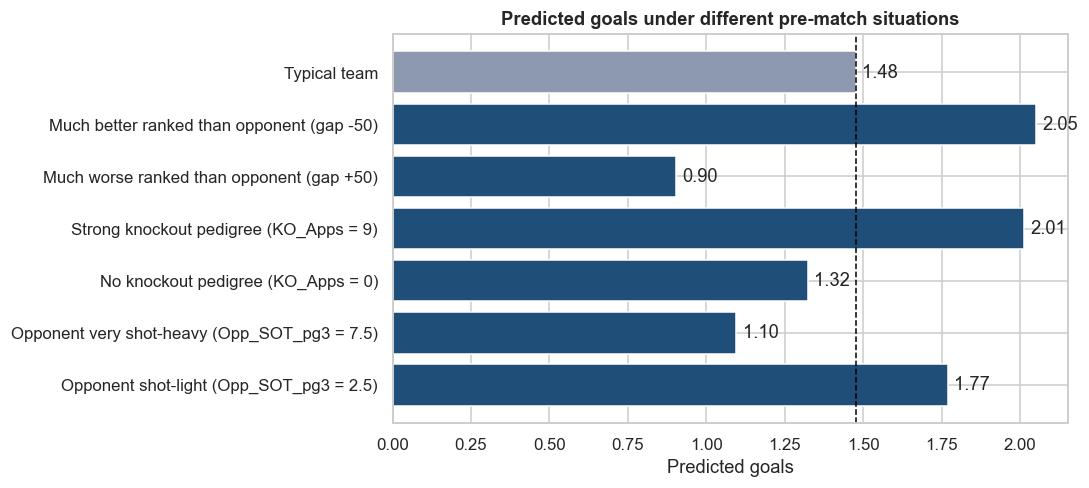

In [36]:
typical = fe_all[POOL].median()

def predict_goals(**changes):
    row = typical.copy()
    for k, v in changes.items():
        row[k] = v
    # keep derived columns consistent with the raw ones
    row["Rank_ssqrt"] = np.sign(row["Rank_Diff"]) * np.sqrt(abs(row["Rank_Diff"]))
    row["SOT_x_OppGK"] = (row["SOT_pg3"] - CENTRE["SOT_pg3"]) * (row["Opp_GK_Saves3"] - CENTRE["Opp_GK_Saves3"])
    return float(final_all.predict(row[FINAL_FEATURES].to_frame().T.astype(float))[0])

scenarios = {
    "Typical team": {},
    "Much better ranked than opponent (gap -50)": {"Rank_Diff": -50},
    "Much worse ranked than opponent (gap +50)": {"Rank_Diff": 50},
    "Strong knockout pedigree (KO_Apps = 9)": {"KO_Apps": 9},
    "No knockout pedigree (KO_Apps = 0)": {"KO_Apps": 0},
    "Opponent very shot-heavy (Opp_SOT_pg3 = 7.5)": {"Opp_SOT_pg3": 7.5},
    "Opponent shot-light (Opp_SOT_pg3 = 2.5)": {"Opp_SOT_pg3": 2.5},
}
sc = pd.Series({k: predict_goals(**v) for k, v in scenarios.items()}, name="Predicted goals")

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(sc.index[::-1], sc.values[::-1], color=[C["main"] if k != "Typical team" else C["grey"] for k in sc.index[::-1]])
ax.axvline(sc["Typical team"], color="black", ls="--", lw=1)
for i, v in enumerate(sc.values[::-1]):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center")
ax.set(title="Predicted goals under different pre-match situations", xlabel="Predicted goals")
plt.tight_layout(); plt.show()

**Reading the scenarios.** A typical team is expected to score about 1.5 goals. A much better-ranked side (gap -50) is expected to score about 2.05 and a much worse-ranked side about 0.90. Strong knockout pedigree (`KO_Apps` = 9) lifts the expectation to about 2.0, and none lowers it to about 1.3. A shot-heavy opponent (7.5 shots on target per game) pulls the expectation down to about 1.1, against about 1.8 for a shot-light one (2.5). These are associations learned from 104 matches, not causal effects.

## Step 14 — Summary, limitations and recommendations

In [37]:
base_cv = cmp.loc["OLS - 8 original"]
fin_cv = cmp.loc[final_name]
print("=" * 70)
print("RESULTS SUMMARY")
print("=" * 70)
print(f"Final model                      : {final_name} ({len(active)} active features of {len(FINAL_FEATURES)})")
print(f"Mean-only reference CV RMSE      : {cmp.loc['Mean-only', 'RMSE']:.3f}")
print(f"OLS 8 original features CV RMSE  : {base_cv['RMSE']:.3f}  (R2 {base_cv['R2']:.3f})")
print(f"Final model CV RMSE              : {fin_cv['RMSE']:.3f}  (R2 {fin_cv['R2']:.3f})")
print(f"Hold-out test RMSE / MAE / R2    : {test_metrics.loc['RMSE', 'Estimate']:.3f} / {test_metrics.loc['MAE', 'Estimate']:.3f} / {test_metrics.loc['R2', 'Estimate']:.3f}")
print(f"Hold-out RMSE 95% CI             : {test_metrics.loc['RMSE', '95% CI low']:.3f} to {test_metrics.loc['RMSE', '95% CI high']:.3f}")
print(f"Full-data repeated CV R2         : {res_full['R2'].mean():.3f}")
print(f"Who-scores-more accuracy         : model {m_acc:.0%} vs FIFA-rank rule {r_acc:.0%} ({len(dec)} non-drawn matches)")
print(f"Best non-linear benchmark RMSE   : {cmp.loc[['Random Forest', 'Gradient Boosting'], 'RMSE'].min():.3f}")
print(f"Poisson GLM CV RMSE              : {cmp.loc['Poisson GLM', 'RMSE']:.3f}")
print("=" * 70)

import sys, sklearn, statsmodels, scipy
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__)

RESULTS SUMMARY
Final model                      : Lasso (8 active features of 18)
Mean-only reference CV RMSE      : 1.392
OLS 8 original features CV RMSE  : 1.246  (R2 0.183)
Final model CV RMSE              : 1.223  (R2 0.212)
Hold-out test RMSE / MAE / R2    : 1.180 / 0.905 / 0.324
Hold-out RMSE 95% CI             : 0.878 to 1.508
Full-data repeated CV R2         : 0.244
Who-scores-more accuracy         : model 85% vs FIFA-rank rule 85% (80 non-drawn matches)
Best non-linear benchmark RMSE   : 1.245
Poisson GLM CV RMSE              : 1.226
Python 3.14.3 | numpy 2.4.2 | pandas 3.0.1 | scikit-learn 1.9.1 | statsmodels 0.15.0


### Key findings

1. **Final model:** a Lasso (L1-regularised) linear regression that predicts a team's goals from pre-match information. Cross-validated RMSE is about 1.22 goals (the mean-only reference is 1.39). On 21 locked hold-out matches, RMSE is about 1.18 (95% range 0.88 to 1.51) and R² about 0.32 (0.07 to 0.48).
2. **The ranking gap alone is as good as the eight original variables.** Real gains came from (a) bringing in the *opponent's* recent form, (b) a square-root transform of the ranking gap, and (c) regularisation, together worth roughly 0.02 goals of RMSE.
3. **More complex models did not help.** Random Forest and Gradient Boosting were no better than linear regression, and a Poisson GLM tied with the regularised linear models, so linear regression is an appropriate choice for this data size.
4. **Selection bias is a real risk.** A feature subset chosen and scored on the same data looked 0.07 goals better than it truly was.
5. **Drivers of goals:** ranking gap and knockout pedigree (essential), the opponent's recent shot volume (clear but smaller), and squad age (small).

### Limitations

- **Small sample.** There are 104 matches (21 in the test set), so every estimate carries wide uncertainty and the hold-out ranking of models is noisy.
- **Modest predictive ceiling.** R² of about 0.2 to 0.3 is realistic for a single football match, where luck plays a large part. Extreme scorelines will always be missed.
- **Assumption departures.** Residuals are right-skewed, their spread grows with the predicted mean, and the two teams in a match share an unmeasured "tempo" effect. Grouped validation, clustered standard errors and the bootstrap mitigate this but do not remove it.
- **Noisy form windows.** A 3-match window is volatile, and early-tournament windows mix friendlies and qualifiers of different quality.
- **Variable definitions.** `Opp_GK_Saves3` is a saves *count* (a measure of shots faced), not a save percentage, and `Striker_Bench_Count` and `KO_Apps` follow your data-collection definitions. State these definitions in the report.
- **Association, not causation.** Coefficients describe patterns in these 104 matches.

### Recommendations

1. **Use the regularised linear model as the working model** and report Ridge, ElasticNet and Poisson as equivalent alternatives. The differences between them are smaller than the noise.
2. **Prioritise data collection** on ranking, tournament pedigree and the opponent's recent shot volume. Own-form variables added nothing once those were present.
3. **Quote uncertainty, not just point predictions.** The 80% band is roughly -1.3 to +1.5 goals around the prediction.
4. **Avoid reading single coefficients of correlated variables** (for example goals and shots on target) in isolation.
5. **Most promising next steps:** add independent strength measures such as Elo ratings or bookmaker odds, use expected-goals data, extend history with earlier tournaments to enlarge the sample, test longer or opponent-adjusted form windows, and fit a match-level model (or a team random effect) to capture the shared tempo effect.